# Brain-age bias correction: linear and quadratic, fitted on all or on normal recordings

📄 **[PDF version](brain_age_bias_correction.pdf)**

Every brain-age model predicts young people too old and old people too young. This notebook explains,
with all formulas and the code that computes them, the post-hoc **age-bias corrections** applied to
the LaBraM brain-age CV experiments in `notebooks/brain_age_research_summary.ipynb` (Table 3.5 there).
In particular it explains the column **`gap quad, normal †`**: the correction of Gemein et al. (2024),
a **quad**ratic age trend of the brain-age gap fitted on **normal** recordings only. It then sets the
corrections against the brain-age literature.

The notebook stands on its own. Sections 1–3 run on synthetic data and need nothing but numpy. Sections 4–5
re-run the corrections on the real per-recording predictions of the four 5-fold CV experiments
(`cvbase`, `cvctrl`, `cvaug`, `cvaugval`). It needs the TUH data volume (`LABRAM_TUH_ROOT`) and is
skipped without it.

| Section | Content |
|---|---|
| 1 | Where the age bias comes from (regression to the mean), Eqs. (1.1)–(1.5) |
| 2 | The corrections: linear / quadratic gap correction, Cole inversion, recalibration, age as covariate, Eqs. (2.1)–(2.10), and their code |
| 3 | Why a gap-corrected MAE is not a prediction error: a model that knows nothing gets MAE 0 |
| 4 | **Step by step on the real data**: which predictions each correction is fitted on (out-of-fold / validation, never test), how the least-squares fit is computed, how it is applied to the TUAB test set |
| 5 | Results of every correction on the four LaBraM CV experiments, TUAB test set |
| 6 | The literature: who uses which correction, and what Gemein et al. did |
| 7 | Summary and recommendations |

The **†** mark follows the research summary: a † method reads the test recording's **true age** when it is
applied. Its "MAE" measures the size of the brain-age gap, not the accuracy of an age estimate.

In [1]:
import inspect
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

if not any(os.path.isdir(os.path.join(p, "labram")) for p in sys.path):
    sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 220)

TUH = os.environ.get("LABRAM_TUH_ROOT", "/data/datasets/EEG-public/TUH_EEG")
CV_PREDS = os.path.join(os.environ.get("LABRAM_CV_EVAL", os.path.join(TUH, "_state/cohort_runs/cv_eval")),
                        "cv_preds.json")
TUEG_INDEX = os.path.join(TUH, "index/tuh_index.parquet")
TUEG_SHEET = os.path.join(TUH, "index/nedc/metadata_v12.xlsm.xlsx")
HAVE_DATA = all(os.path.exists(p) for p in (CV_PREDS, TUEG_INDEX, TUEG_SHEET))
print(f"per-recording CV predictions and TUH index: {'found' if HAVE_DATA else 'not found (Sections 4-5 skipped)'}")


def finish(fig, axes=None):
    fig.tight_layout()                       # lay out first: panel_labels sorts by position
    if axes is not None and len(axes) > 1:
        panel_labels(axes)
    assert_max_columns(fig)
    plt.show()

per-recording CV predictions and TUH index: found


## 1. Where the age bias comes from

For a recording $i$ with true (chronological) age $y_i$ and predicted age $\hat y_i$, both in years, the
**brain-age gap** (also called brain-age delta, BAG or PAD) is

$$ e_i = \hat y_i - y_i \quad\text{(years)}. \tag{1.1} $$

Over a set $S$ of recordings the error and the mean gap are

$$ \mathrm{MAE}(S) = \frac{1}{|S|}\sum_{i\in S}\lvert e_i\rvert, \qquad
   \mathrm{bias}(S) = \frac{1}{|S|}\sum_{i\in S} e_i . \tag{1.2} $$

The **bias slope** is the least-squares slope of the gap against the true age (population moments over
$S$; `labram/utils/regression_metrics.py::age_bias_slope`, `labram/eval/research_summary.py::age_fit_metrics`):

$$ \beta(S) = \frac{\operatorname{Cov}_S(y, e)}{\operatorname{Var}_S(y)} . \tag{1.3} $$

$\beta = 0$: the gap does not depend on age. $\beta = -1$: the prediction is a constant. $\beta = -0.4$:
someone 10 years older than average is predicted 4 years too young.

**Why $\beta < 0$ is the normal case.** A regression model trained with a squared (or Huber, or L1)
loss estimates the conditional mean $\hat y = \mathrm E[y \mid x]$ of the age given the EEG $x$. For such
an estimate the prediction is uncorrelated with its own residual, $\operatorname{Cov}(\hat y, y - \hat y) = 0$,
so $\operatorname{Cov}(y, \hat y) = \operatorname{Var}(\hat y)$, and with the coefficient of determination

$$ R^2 = 1 - \frac{\operatorname{Var}(y - \hat y)}{\operatorname{Var}(y)} = \frac{\operatorname{Var}(\hat y)}{\operatorname{Var}(y)} \tag{1.4} $$

the bias slope follows directly:

$$ \beta = \frac{\operatorname{Cov}(y, \hat y) - \operatorname{Var}(y)}{\operatorname{Var}(y)}
        = \frac{\operatorname{Var}(\hat y)}{\operatorname{Var}(y)} - 1 = R^2 - 1 . \tag{1.5} $$

So **any** imperfect but well-trained model shrinks its predictions toward the mean age, by exactly the
share of the age variance it cannot explain (Liang et al. 2019; Smith et al. 2019; Butler et al. 2021 derive
the same). The bias is not a bug of one model. It is what least squares does when the EEG carries only part
of the age information. Eq. (1.5) holds exactly in-sample for an OLS fit with intercept, and approximately
for a held-out set.

**Synthetic example.** Ages $y \sim \mathcal N(50, 18^2)$ clipped to 18–90 years. One "EEG age feature"
$x = 45\big(1 - e^{-(y - 10)/30}\big) + \varepsilon$, $\varepsilon \sim \mathcal N(0, 5^2)$, changes fast in
young adults and saturates at old age, like many EEG markers. The "model" is the OLS line of $y$ on $x$, fitted on a training
sample of 5,000 and applied to two further samples of 5,000: a **fit set** $F$ (used to fit the corrections
of Section 2) and a **test set** $T$ (scored).

In [2]:
rng = np.random.default_rng(0)


def draw(n):
    y = np.clip(rng.normal(50, 18, n), 18, 90)
    x = 45 * (1 - np.exp(-(y - 10) / 30)) + rng.normal(0, 5, n)
    return x, y


x_tr, y_tr = draw(5000)
w1, w0 = np.polyfit(x_tr, y_tr, 1)                  # the "model": OLS of age on the feature
syn = {}
for name in ("fit", "test"):
    x, y = draw(5000)
    syn[name] = pd.DataFrame({"true": y, "pred": w1 * x + w0})
    syn[name]["err"] = syn[name].pred - syn[name].true   # Eq. (1.1)


def describe(pred, true):
    # MAE / bias (1.2), beta (1.3), R^2 (1.4) and R^2 - 1, the beta that Eq. (1.5) predicts
    p, t = np.asarray(pred, float), np.asarray(true, float)
    e = p - t
    r2 = 1 - np.var(e) / np.var(t) if np.var(t) > 0 else np.nan
    beta = np.mean((t - t.mean()) * (e - e.mean())) / np.var(t)
    return {"n": len(t), "MAE": np.mean(np.abs(e)), "bias": e.mean(), "β (1.3)": beta,
            "R² (1.4)": r2, "R² − 1 (1.5)": r2 - 1}

### Table 1.1. The synthetic model is biased exactly as Eq. (1.5) predicts

One row per synthetic sample: `n` recordings, `MAE` and `bias` (Eq. (1.2)), `β` (Eq. (1.3)), `R²`
(Eq. (1.4), $1 - \operatorname{Var}(e)/\operatorname{Var}(y)$) and `R² − 1`, the slope Eq. (1.5) predicts.
`train` is the model's own training sample, where Eq. (1.5) is exact.

In [3]:
syn_train = pd.DataFrame({"true": y_tr, "pred": w1 * x_tr + w0})
t11 = pd.DataFrame({k: describe(d.pred, d.true) for k, d in
                    {"train": syn_train, "fit set F": syn["fit"], "test set T": syn["test"]}.items()}).T
display(numbered_table(t11.style.format(precision=3).format("{:,.0f}", subset=["n"]), "1.1",
                       "Synthetic model: bias slope against R² − 1"))

,n,MAE,bias,β (1.3),R² (1.4),R² − 1 (1.5)
train,"5,000",8.111,-0.000,-0.358,0.642,-0.358
fit set F,"5,000",8.040,-0.256,-0.367,0.643,-0.357
test set T,"5,000",7.993,-0.187,-0.348,0.644,-0.356


### Figure 1.1. Regression to the mean in the synthetic model

Synthetic test set $T$, $n = 5{,}000$, ages in years. (a) Predicted against true age; the dashed line is the
identity, the orange dots the mean prediction per 5-year age bin. (b) The gap $e$ of Eq. (1.1) against the
true age, with the least-squares line (slope $\beta$ of Eq. (1.3)) and the least-squares quadratic of
Eq. (2.2) below.

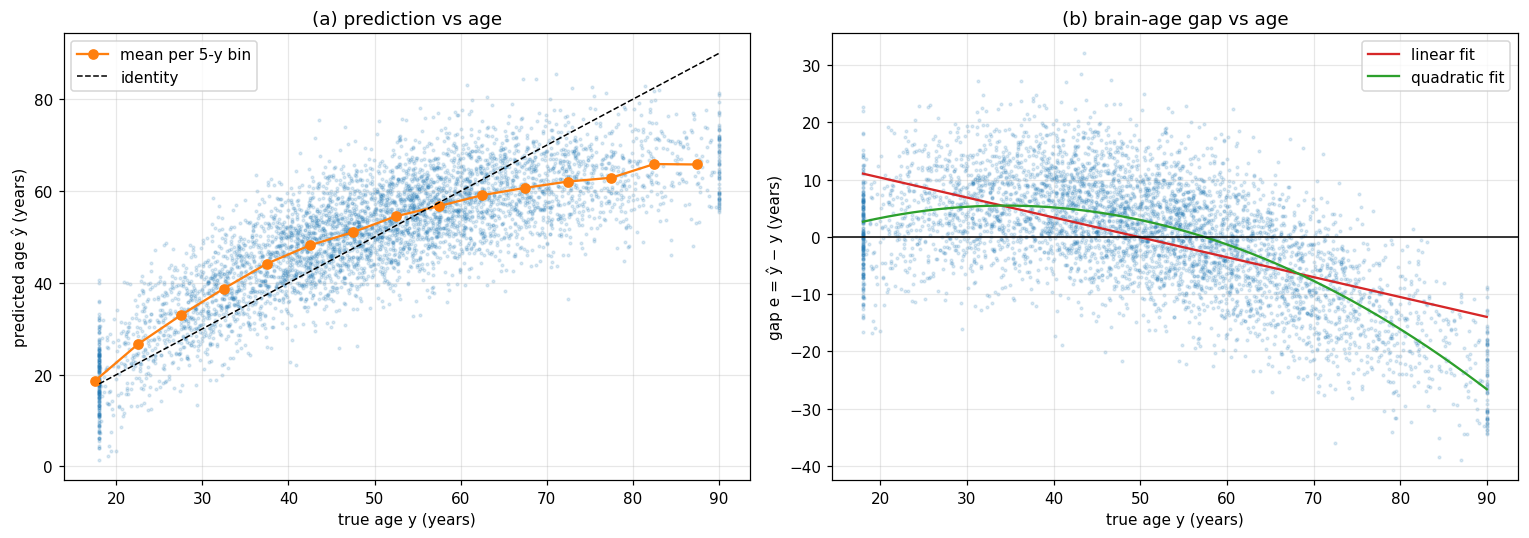

In [4]:
d = syn["test"]
bins = np.arange(15, 95, 5)
mid = (bins[:-1] + bins[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(d.true, d.pred, s=3, alpha=0.15, color="tab:blue")
b = pd.cut(d.true, bins)
ax.plot(mid, d.groupby(b, observed=False).pred.mean(), "o-", color="tab:orange", label="mean per 5-y bin")
ax.plot([18, 90], [18, 90], "k--", lw=1, label="identity")
ax.set(xlabel="true age y (years)", ylabel="predicted age ŷ (years)", title="prediction vs age")
ax.legend()
ax = axes[1]
ax.scatter(d.true, d.err, s=3, alpha=0.15, color="tab:blue")
grid = np.linspace(18, 90, 200)
ax.plot(grid, np.polyval(np.polyfit(d.true, d.err, 1), grid), color="tab:red", label="linear fit")
ax.plot(grid, np.polyval(np.polyfit(d.true, d.err, 2), grid), color="tab:green", label="quadratic fit")
ax.axhline(0, color="k", lw=1)
ax.set(xlabel="true age y (years)", ylabel="gap e = ŷ − y (years)", title="brain-age gap vs age")
ax.legend()
finish(fig, axes)

The synthetic model's gap falls with age (Figure 1.1(b)), with $\beta$ equal to $R^2 - 1$ (Table 1.1): exactly
on its training sample, within sampling noise on the fit and test sets. Because the feature saturates at
old age, the gap also bends down there: the linear fit misses the curvature that the quadratic captures.
That curvature is the reason to use a quadratic correction (Smith et al. 2019; Gemein et al. 2024).

## 2. The corrections

All corrections have two steps: **fit** a few coefficients on a fit set $F$ of recordings with known
age, then **apply** them to the test predictions. They differ in what the application step reads.

**Fit set.** In the CV experiments of Section 4, $F$ is the set of out-of-fold predictions: every
recording $j$ of the CV pool, predicted by the one fold model that did not train on it. Optionally
only the normal recordings are kept:

$$ \begin{aligned} F &= \lbrace j \in \text{out-of-fold} : \text{status}_j \in \mathcal S \rbrace, \\
   \mathcal S &= \lbrace\text{normal}\rbrace \ \text{(“normal”)} \ \text{or all statuses (“all”)} . \end{aligned} \tag{2.1} $$

$F$ shares no recording and no patient with the test set (Table 5.2).

### 2.1 Gap correction, linear or quadratic (†)

Fit the gap as a polynomial of degree $d$ in the true age, by least squares over $F$
(`np.polyfit(true, err, d)`):

$$ (q_0, \dots, q_d) = \arg\min_{q} \sum_{j\in F}\Big(e_j - \sum_{k=0}^{d} q_k\,y_j^{k}\Big)^2, \qquad
   p_d(y) = \sum_{k=0}^{d} q_k\,y^{k} . \tag{2.2} $$

Subtract the fitted trend, evaluated at the test recording's **true** age:

$$ \hat y^{\,c}_i = \hat y_i - p_d(y_i), \qquad e^{c}_i = \hat y^{\,c}_i - y_i = e_i - p_d(y_i) . \tag{2.3} $$

* $d = 1$, **`gap lin`**: Beheshti et al. (2019), de Lange & Cole (2020), Smith et al. (2019) "$\delta_2$",
  Liang et al. (2019).
* $d = 2$, **`gap quad`**: Smith et al. (2019) "$\delta_{2q}$"; Gemein et al. (2024), fitted during CV on
  their training data, which hold non-pathological recordings only. **`gap quad, normal`** reproduces that
  choice: $d = 2$ and $\mathcal S = \lbrace\text{normal}\rbrace$.

On $F$ itself, $e^c$ is the least-squares residual of $e$ on $(1, y, \dots, y^d)$, so it has mean 0 and no
correlation with $y, \dots, y^d$. Applied with the true age, the correction removes the age trend from any
set drawn like $F$.

**The de Lange & Cole form is the same correction.** If $\hat y \approx a\,y + c$ on $F$ (the fit of Eq. (2.5)),
then $e \approx (a - 1)\,y + c$, so $p_1(y) = (a-1)\,y + c$ and Eq. (2.3) becomes

$$ \hat y^{\,c}_i = \hat y_i + \big[\,y_i - (a\,y_i + c)\,\big] , \tag{2.4} $$

the "corrected predicted age = predicted age + [age − (α·age + β)]" of de Lange et al. (2019) and de Lange & Cole
(2020), and the "predicted age − offset" of Beheshti et al. (2019). In the code base it is also
`labram/eval/age_analysis.py::apply_bias_correction(..., "age_level")` and
`labram/eval/cv_compare.py::bias_correct`.

### 2.2 Cole inversion (deployable)

Fit the prediction as a line in the age over $F$ and invert it (Cole et al. 2018):

$$ (a, c) = \arg\min_{a,c}\sum_{j\in F}\big(\hat y_j - a\,y_j - c\big)^2, \qquad
   \hat y'_i = \frac{\hat y_i - c}{a} . \tag{2.5} $$

It reads only the prediction $\hat y_i$, so it is a valid age estimate on a new patient. With the same $F$,
it is the linear gap correction divided by $a$, recording by recording:

$$ \hat y'_i - y_i = \frac{\hat y_i - a\,y_i - c}{a} = \frac{e_i - \big((a-1)\,y_i + c\big)}{a}
   = \frac{e^{c}_i}{a} . \tag{2.6} $$

Since $a = 1 + \beta < 1$, the Cole error is the gap-corrected error **inflated** by $1/a$: removing the
age trend without the true age means spreading the predictions, and their noise with them.

### 2.3 Recalibration, linear or quadratic (deployable)

Regress the true age on the prediction over $F$ and map the test prediction through it:

$$ (b_0, \dots, b_d) = \arg\min_{b}\sum_{j\in F}\Big(y_j - \sum_{k=0}^{d} b_k\,\hat y_j^{\,k}\Big)^2, \qquad
   \hat y''_i = \sum_{k=0}^{d} b_k\,\hat y_i^{\,k} . \tag{2.7} $$

$d = 1$ (`recal lin`, $\hat y'' = a'\hat y + b'$) is the correction in the `cal.` columns of the research
summary (its Eqs. (2.14), (3.11)). $d = 2$ (`recal quad`) is a deployable analogue of the quadratic gap
correction added here for comparison. For $d = 1$ the two slopes are tied by the squared correlation
$r^2_F$ of $\hat y$ and $y$ on $F$:

$$ a' = \frac{\operatorname{Cov}_F(\hat y, y)}{\operatorname{Var}_F(\hat y)}, \quad
   a = \frac{\operatorname{Cov}_F(\hat y, y)}{\operatorname{Var}_F(y)}
   \quad\Longrightarrow\quad a\,a' = r^2_F . \tag{2.8} $$

For a model that is already least-squares calibrated, $a = R^2 = r^2$ (Eq. (1.5)), so $a' = 1$: recalibration
has nothing left to do, while Cole multiplies by $1/a$. Recalibration minimises the squared error; it does
**not** remove the age trend of the gap (it keeps or strengthens the shrinkage).

### 2.4 Age as a covariate (group comparisons)

For a group question (do abnormal recordings look older?) the literature recommends leaving the gap
uncorrected and adding age to the model instead (Le et al. 2018; de Lange & Cole 2020; Butler et al. 2021):

$$ e_i = \gamma_0 + \gamma_1\,y_i + \gamma_2\,y_i^2 + \delta\,\mathbb 1[\text{abnormal}_i] + \varepsilon_i , \tag{2.9} $$

fitted by OLS over the analysed set, where $\delta$ is the age-adjusted gap difference between abnormal and normal recordings, in years.

### 2.5 Scoring

A corrected prediction $\tilde y_i \in \lbrace \hat y^{\,c}_i, \hat y'_i, \hat y''_i\rbrace$ is scored like a raw one:

$$ \mathrm{MAE}^{\text{method}}(S) = \frac{1}{|S|}\sum_{i\in S}\lvert\tilde y_i - y_i\rvert . \tag{2.10} $$

For the deployable methods this is a test error. For the † gap correction it is the mean absolute
age-detrended gap, which is not comparable with an MAE (Section 3).

### Table 2.1. The corrections at a glance

| name in this notebook | equations | fitted on $F$ | applied to test recording $i$ with | deployable on a new patient | removes the age trend of the gap | literature |
|---|---|---|---|---|---|---|
| `raw` | (1.1) | – | – | yes | no | – |
| `gap lin` † | (2.2)–(2.4), $d=1$ | $e$ on $y$ | $\hat y_i$ **and** $y_i$ | no | yes | Beheshti 2019; de Lange & Cole 2020; Smith 2019 ($\delta_2$); Liang 2019 |
| `gap quad` † | (2.2)–(2.3), $d=2$ | $e$ on $y, y^2$ | $\hat y_i$ **and** $y_i$ | no | yes, also curvature | Smith 2019 ($\delta_{2q}$); Gemein 2024 (normal) |
| `cole` | (2.5)–(2.6) | $\hat y$ on $y$ | $\hat y_i$ | yes | yes, on average (noise $\times 1/a$) | Cole 2018 |
| `recal lin` | (2.7)–(2.8), $d=1$ | $y$ on $\hat y$ | $\hat y_i$ | yes | no (least-squares optimal) | standard calibration |
| `recal quad` | (2.7), $d=2$ | $y$ on $\hat y, \hat y^2$ | $\hat y_i$ | yes | no | added here |
| age covariate | (2.9) | – (fitted on the analysed set) | – | – | for group effects | Le 2018; Butler 2021; de Lange & Cole 2020 |

`, all` / `, normal` after a name gives the status set $\mathcal S$ of Eq. (2.1).

### 2.6 The code

The functions below implement Eqs. (2.2)–(2.7) on arrays, and the per-experiment versions on the
prediction table of Section 4 (one row per experiment × recording: `exp`, `set`, `stem`, `pred`, `true`,
`err`, `status`). They are written out here so the notebook is self-contained. They reproduce exactly the
functions that produced Table 3.5 of the research summary (`labram/eval/research_summary.py`:
`bias_corrected_test`, `cole_corrected_test`, `recalibrated_test`), which Section 5 checks. Every fit uses
`np.polyfit`, i.e. ordinary least squares.

In [5]:
# --- array level --------------------------------------------------------------------------------------
def fit_gap(true_fit, err_fit, degree):
    # Eq. (2.2): least squares of the gap e on a polynomial of degree d in the true age y
    return np.polyfit(true_fit, err_fit, degree)


def apply_gap(pred, true, coef):
    # Eq. (2.3): subtract the fitted trend at the recording's TRUE age  (†: reads y_i)
    return np.asarray(pred, float) - np.polyval(coef, np.asarray(true, float))


def fit_cole(true_fit, pred_fit):
    # Eq. (2.5): least squares of the prediction on the age, pred ~ a * y + c
    a, c = np.polyfit(true_fit, pred_fit, 1)
    return a, c


def apply_cole(pred, a, c):
    # Eq. (2.5): invert the line; reads the prediction only
    return (np.asarray(pred, float) - c) / a


def fit_recal(pred_fit, true_fit, degree=1):
    # Eq. (2.7): least squares of the age on a polynomial of the prediction
    return np.polyfit(pred_fit, true_fit, degree)


def apply_recal(pred, coef):
    # Eq. (2.7): map the prediction through the fitted polynomial; reads the prediction only
    return np.polyval(coef, np.asarray(pred, float))


# --- per experiment on the prediction table of Section 4 -----------------------------------------------
TEST_SET = "TUAB test, ensemble"
OOF_SETS = ("TUAB out-of-fold", "TUEG out-of-fold")


def fit_set(g, statuses=None):
    # Eq. (2.1): the out-of-fold recordings of one experiment, optionally of the given statuses
    f = g[g.set.isin(OOF_SETS)]
    return f if statuses is None else f[f.status.isin(statuses)]


def corrected_test(sets, method, degree=1, statuses=None):
    # the TUAB test rows of every experiment with `pred` / `err` corrected by `method`
    out = []
    for exp, g in sets.groupby("exp", sort=False):
        f = fit_set(g, statuses)
        t = g[g.set == TEST_SET].copy()
        if method == "gap":                                       # Eqs. (2.2)-(2.3)  †
            t["pred"] = apply_gap(t.pred, t.true, fit_gap(f.true, f.err, degree))
        elif method == "cole":                                    # Eq. (2.5)
            t["pred"] = apply_cole(t.pred, *fit_cole(f.true, f.pred))
        elif method == "recal":                                   # Eq. (2.7)
            t["pred"] = apply_recal(t.pred, fit_recal(f.pred, f.true, degree))
        elif method != "raw":
            raise ValueError(method)
        t["err"] = t.pred - t.true                                # Eq. (1.1)
        out.append(t)
    return pd.concat(out, ignore_index=True)


NORMAL = ("normal",)
METHODS = {   # name -> sets -> corrected TUAB test rows.  † = applied with the test recording's true age
    "raw": lambda s: corrected_test(s, "raw"),
    "recal lin, normal": lambda s: corrected_test(s, "recal", 1, NORMAL),
    "recal quad, normal": lambda s: corrected_test(s, "recal", 2, NORMAL),
    "cole, normal": lambda s: corrected_test(s, "cole", statuses=NORMAL),
    "cole, all": lambda s: corrected_test(s, "cole"),
    "gap lin, all †": lambda s: corrected_test(s, "gap", 1),
    "gap lin, normal †": lambda s: corrected_test(s, "gap", 1, NORMAL),
    "gap quad, all †": lambda s: corrected_test(s, "gap", 2),
    "gap quad, normal †": lambda s: corrected_test(s, "gap", 2, NORMAL),
}
DEPLOYABLE = [m for m in METHODS if "†" not in m]
GAP = [m for m in METHODS if "†" in m]

## 3. Why a gap-corrected MAE is not a prediction error

Eq. (2.3) subtracts a function of the true age $y_i$ from the prediction. That alone can make a useless
model look perfect. Take a model that always predicts the same age $m$: its gap $e = m - y$ is exactly
linear in $y$, so Eq. (2.2) with $d = 1$ finds $p_1(y) = m - y$ and Eq. (2.3) returns

$$ \hat y^{\,c}_i = m - (m - y_i) = y_i, \qquad \mathrm{MAE}^{\text{gap lin}} = 0 . \tag{3.1} $$

A model that outputs pure noise, $\hat y = m + \eta$ with $\eta$ independent of $y$, ends at
$\hat y^{\,c}_i - y_i \approx \eta_i - \bar\eta_F$, so

$$ \mathrm{MAE}^{\text{gap lin}} \approx \mathrm E\,\lvert\eta - \mathrm E\eta\rvert, \tag{3.2} $$

the noise level, however little the model knows about age. Butler et al. (2021) show the same for $R^2$:
after this correction $R^2$ is high almost regardless of the true model accuracy, and de Lange et al. (2022)
show that corrected metrics depend on the cohort's age range. The corrected gap is meaningful (it is
the brain-age gap net of age, the quantity a group comparison needs), but its MAE says nothing about how
well the model estimates age.

### Table 3.1. MAE after each correction, for a real and two useless synthetic predictors

Synthetic data of Section 1. Every correction is fitted on the fit set $F$ and scored on the test set $T$
($n = 5{,}000$ each), MAE in years (Eq. (2.10)). Rows: `model` is the OLS model of Section 1; `constant`
predicts the training mean age for everyone; `noise (sd 8)` predicts the training mean plus Gaussian noise
of 8 years, independent of age. Columns: `R²` of the raw prediction (Eq. (1.4)); `raw` (Eq. (1.2));
`recal lin` / `recal quad` (Eq. (2.7)); `cole` (Eq. (2.5); undefined for a constant, where $a = 0$);
`gap lin †` / `gap quad †` (Eqs. (2.2)–(2.3)). There is no status here, so every fit uses all of $F$.

In [6]:
def all_corrections(fit, test):
    # every correction of Section 2 fitted on `fit`, scored on `test`: MAE (2.10), years
    out = {"R²": describe(test.pred, test.true)["R² (1.4)"], "raw": np.mean(np.abs(test.err))}
    for d, name in ((1, "lin"), (2, "quad")):
        out[f"recal {name}"] = np.mean(np.abs(apply_recal(test.pred, fit_recal(fit.pred, fit.true, d)) - test.true))
    a, c = fit_cole(fit.true, fit.pred)
    out["cole"] = np.mean(np.abs(apply_cole(test.pred, a, c) - test.true)) if abs(a) > 1e-6 else np.nan
    for d, name in ((1, "lin"), (2, "quad")):
        out[f"gap {name} †"] = np.mean(np.abs(apply_gap(test.pred, test.true, fit_gap(fit.true, fit.err, d)) - test.true))
    return out


def predictor(kind, d):
    p = {"model": d.pred, "constant": np.full(len(d), y_tr.mean()),
         "noise (sd 8)": y_tr.mean() + rng.normal(0, 8, len(d))}[kind]
    return pd.DataFrame({"true": d.true, "pred": p, "err": p - d.true})


t31 = pd.DataFrame({k: all_corrections(predictor(k, syn["fit"]), predictor(k, syn["test"]))
                    for k in ("model", "constant", "noise (sd 8)")}).T
display(numbered_table(t31, "3.1", "Synthetic: MAE after each correction"))

,R²,raw,recal lin,recal quad,cole,gap lin †,gap quad †
model,0.64,7.99,8.02,7.98,10.44,6.61,5.95
constant,0.00,13.89,13.89,13.89,–,0.00,0.00
noise (sd 8),-0.21,15.16,13.89,13.90,10834.63,6.32,6.33


### Figure 3.1. The gap correction turns a noise predictor into an apparently good age model

Synthetic test set $T$, $n = 5{,}000$, the `noise (sd 8)` predictor of Table 3.1, years. (a) Its raw
prediction against the true age: no age information at all ($R^2 \le 0$). (b) The same predictions after
`gap lin †` (Eq. (2.3)), fitted on $F$: they now lie along the identity, with the noise of the raw
prediction as their only error.

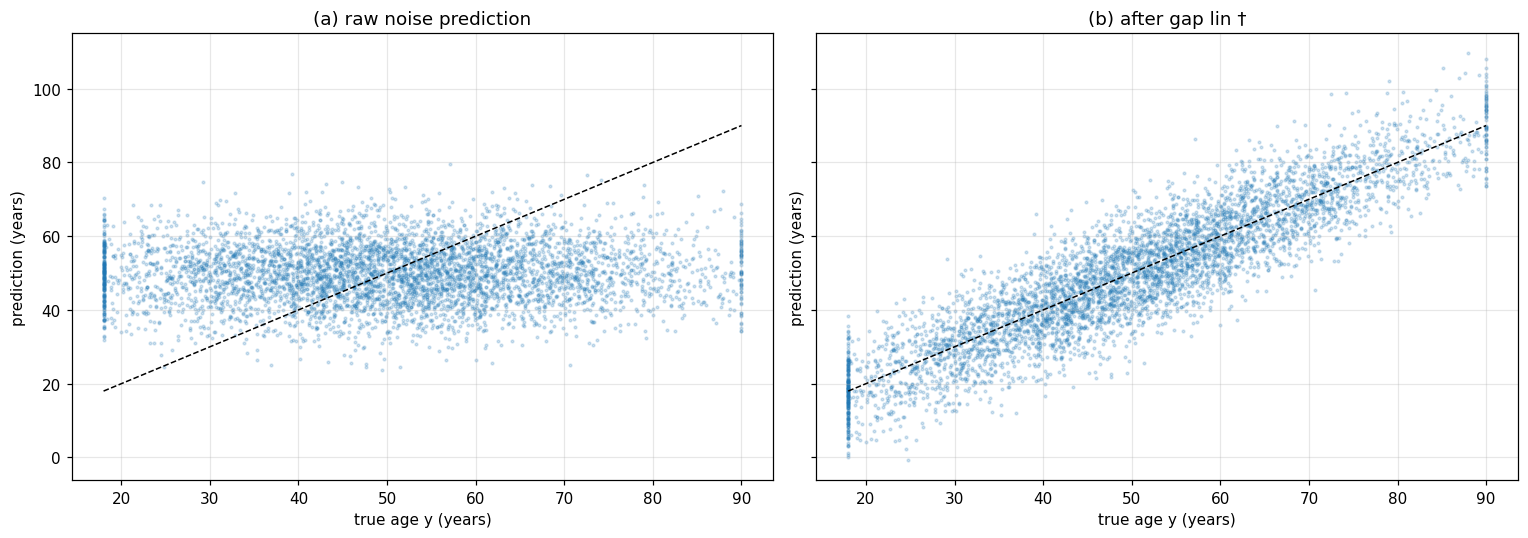

In [7]:
fit_n, test_n = predictor("noise (sd 8)", syn["fit"]), predictor("noise (sd 8)", syn["test"])
corr_n = apply_gap(test_n.pred, test_n.true, fit_gap(fit_n.true, fit_n.err, 1))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, p, title in ((axes[0], test_n.pred, "raw noise prediction"), (axes[1], corr_n, "after gap lin †")):
    ax.scatter(test_n.true, p, s=3, alpha=0.2)
    ax.plot([18, 90], [18, 90], "k--", lw=1)
    ax.set(xlabel="true age y (years)", ylabel="prediction (years)", title=title)
finish(fig, axes)

Table 3.1 and Figure 3.1 make the point concrete. The constant predictor scores a gap-corrected MAE of
0 (Eq. (3.1)), and the noise predictor scores its own noise level, about $8\sqrt{2/\pi} \approx 6.4$ years
(Eq. (3.2)). Both beat the real model's raw MAE, although neither knows anything about age; the noise
predictor even beats the real model's own `gap lin †` number. The
deployable corrections cannot be gamed this way: `recal` turns both useless predictors into the mean age
(MAE equal to the age spread), and `cole` is undefined for the constant and explodes for the noise. For
the real model, `cole` is worse than `raw` by about the factor $1/a$ of Eq. (2.6), and `recal lin` changes
nothing, because the OLS model is already least-squares calibrated (Eq. (2.8) with $a' = 1$); `recal quad`
gains nothing either. The gap corrections lower the real model's number, and the quadratic more than the
linear one, because it also removes the bend of Figure 1.1(b).

## 4. Step by step: what each correction is fitted on and applied to

> **Short answer.** For the CV experiments, the linear and the quadratic correction were **not fitted on
> the test set** and not on a split that chose the model. They were fitted on the **out-of-fold
> predictions** of the CV pool: the 29,035 TUAB + TUEG train/val recordings, each predicted by the one fold
> model whose **in-pool test fold** held it out. The corrections were then **applied to the TUAB test
> set**: 274 recordings outside the CV pool, predicted by the median of the 5 fold models. `, normal`
> means only the 11,455 normal recordings of that pool were used for the fit; `, all` uses all 29,035.
> Exception: `cvaugval` has no in-pool test fold, so its fit set is its **validation** folds (Section 4.1).
> The only corrections fitted on a run's own **validation split** are the `cal.` columns of the research
> summary's Table 2.5 for single-split runs: a *linear recalibration* (no quadratic, no gap correction),
> fitted on the normal val recordings and applied to the test predictions (Table 4.9). Validation MAEs
> are never corrected.

**How it works, in words.** A correction learns, from recordings whose age is known and that the model
did not train on, *how wrong the model typically is at each age*: "30-year-olds are predicted about 6 years
too old, 75-year-olds about 11 years too young". That is the curve $p(y)$ of Eq. (2.2), a straight line
(linear) or a parabola (quadratic). For each test recording it then looks up the typical error at that
recording's age and removes it, Eq. (2.3). What is left is how much *this* recording deviates from a
typical recording of the same age: the corrected brain-age gap. The steps below do this for `cvctrl`
with real numbers:

| step | what happens | data | Table / Figure |
|---|---|---|---|
| 0 | the CV pool is cut into 5 folds; fold model $k$ trains on 3, picks its epoch on 1, predicts 1 | CV pool (TUAB + TUEG train/val) | Figure 4.1, Table 4.1 |
| 1 | predict: every pool recording once (out-of-fold), every TUAB test recording 5 times → median | pool, TUAB test | Tables 4.2, 4.3 |
| 2 | collect the fit set $F$: the out-of-fold predictions, all or only normal | pool only | Table 4.4 |
| 3 | fit $p(y)$ by least squares on $F$ (linear: 2 numbers, quadratic: 3) | $F$ | Tables 4.5, 4.6 |
| 4 | apply $p$ to each TUAB test recording at its true age | TUAB test | Table 4.7, Figure 4.2 |
| 5 | score: MAE over the 274 / 149 / 125 TUAB test recordings | TUAB test | Table 4.8 |

### 4.1 Step 0: the cross-validation layout

The CV pool $P$ (29,035 recordings of TUAB train + val and TUEG train + val, cohort `all_both_v3_cvcompact`)
is split into 5 patient-disjoint folds $P_0, \dots, P_4$. In `cvbase`, `cvctrl` and `cvaug`, fold model
$k \in \lbrace 0, \dots, 4\rbrace$ uses

$$ \begin{aligned} \text{test}_k &= P_k, \qquad \text{val}_k = P_{(k+1) \bmod 5}, \\
   \text{train}_k &= P \setminus (P_k \cup P_{(k+1) \bmod 5}) , \end{aligned} \tag{4.1} $$

so it trains on 3 folds, chooses its best epoch on the val fold and predicts its test fold. `cvaugval` (val-only
CV) uses $\text{val}_k = P_k$ and trains on the other 4 folds; it has no in-pool test fold. Every fold model also
predicts the TUAB test set $T$, which is in no fold. The **out-of-fold prediction** of a pool recording $j$
is the prediction of the one model that held it out,

$$ \hat y^{\,\text{oof}}_j = f_{k(j)}(x_j), \qquad k(j) : j \in P_{k(j)} , \tag{4.2} $$

(the test fold for `cvbase`/`cvctrl`/`cvaug`; the val fold for `cvaugval`, `rs.CV_OOF_SPLIT`), and the
prediction of a TUAB test recording is the median over the 5 fold models (research summary Eq. (3.8)):

$$ \hat y_i = \operatorname{median}_{k=0,\dots,4} f_k(x_i), \qquad i \in T . \tag{4.3} $$

Here $f_k(x)$ is fold model $k$'s recording-level predicted age (mean over the recording's windows), in years.

### Figure 4.1. Which fold each fold model trains on, validates on and predicts

Rows: the 5 fold models; columns: the 5 folds of the CV pool and the TUAB test set. Colour: blue = trains on
it, orange = chooses its epoch on it (val), green = its predictions of these recordings form the fit set
$F$ of the corrections (Eq. (4.2)), red = TUAB test, predicted by every model and corrected (Eq. (4.3)).
(a) `cvbase`, `cvctrl`, `cvaug` (Eq. (4.1)); (b) `cvaugval`, whose fit set is its val folds.

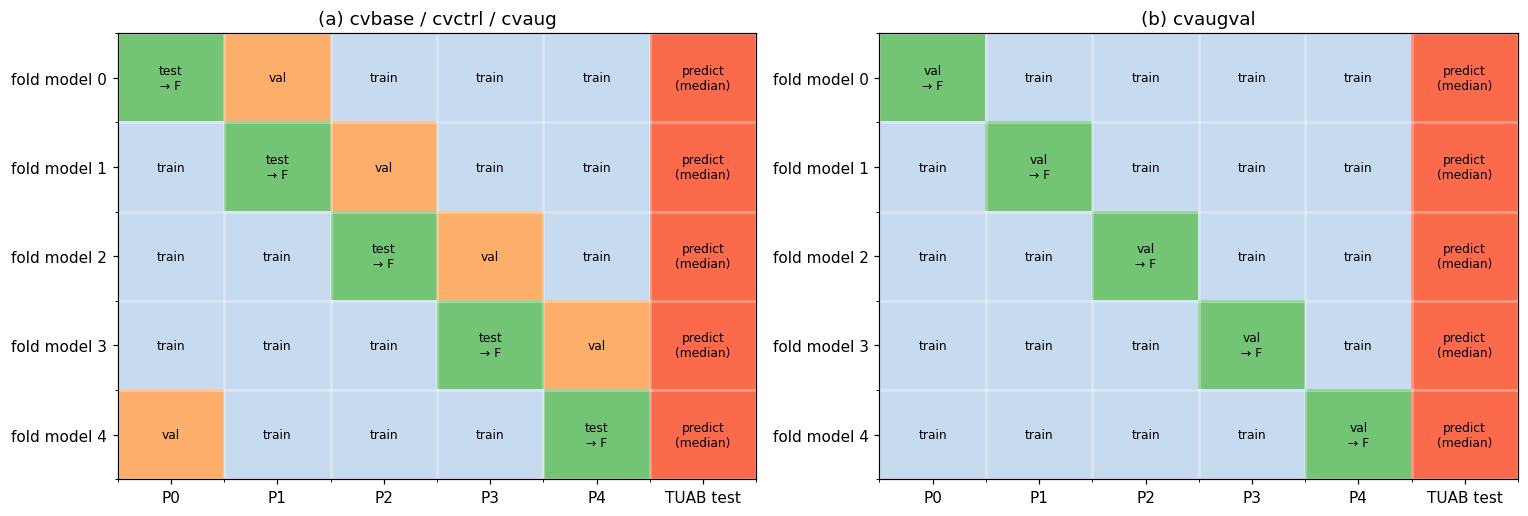

In [8]:
from matplotlib.colors import ListedColormap

ROLE_COLORS = ["#c6dbef", "#fdae6b", "#74c476", "#fb6a4a"]      # train, val, -> F, TUAB test


def fold_layout(val_only):
    # role of every (fold model k, fold j) cell, Eq. (4.1); last column = TUAB test
    code_, text = np.zeros((5, 6), int), [[""] * 6 for _ in range(5)]
    for k in range(5):
        for j in range(5):
            if val_only:
                r, t = (2, "val\n→ F") if j == k else (0, "train")
            elif j == k:
                r, t = 2, "test\n→ F"
            elif j == (k + 1) % 5:
                r, t = 1, "val"
            else:
                r, t = 0, "train"
            code_[k, j], text[k][j] = r, t
        code_[k, 5], text[k][5] = 3, "predict\n(median)"
    return code_, text


fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, val_only, title in ((axes[0], False, "cvbase / cvctrl / cvaug"), (axes[1], True, "cvaugval")):
    c, t = fold_layout(val_only)
    ax.imshow(c, cmap=ListedColormap(ROLE_COLORS), vmin=0, vmax=3, aspect="auto")
    for k in range(5):
        for j in range(6):
            ax.text(j, k, t[k][j], ha="center", va="center", fontsize=8)
    ax.set_xticks(range(6), [f"P{j}" for j in range(5)] + ["TUAB test"])
    ax.set_yticks(range(5), [f"fold model {k}" for k in range(5)])
    ax.set_xticks(np.arange(-0.5, 6), minor=True)
    ax.set_yticks(np.arange(-0.5, 5), minor=True)
    ax.grid(which="minor", color="w", lw=2)
    ax.grid(which="major", visible=False)
    ax.set_title(title)
finish(fig, axes)

In [9]:
psets = None
if HAVE_DATA:
    from labram.eval import cv_compare as cc
    from labram.eval import research_summary as rs
    preds = cc.long_frame(cc.load_predictions(CV_PREDS))      # exp, fold, split (val/test/heldout), stem, pred, true
    tueg = rs.tueg_recordings(TUEG_INDEX, TUEG_SHEET)         # recording -> status, corpora
    psets = rs.prediction_sets(preds, tueg)                   # Eqs. (4.2), (4.3) with status
    EXPS = list(dict.fromkeys(psets.exp))
    print(f"{len(psets):,} prediction rows; experiments: {', '.join(EXPS)}")
else:
    print("CV predictions / TUH index not found: set LABRAM_TUH_ROOT (and LABRAM_CV_EVAL). Sections 4.2-5 skipped.")

117,236 prediction rows; experiments: cvaug, cvaugval, cvbase, cvctrl


### Table 4.1. The five fold models of `cvctrl`

One row per fold model $k$ (Eq. (4.1)): the folds it trains on, chooses its epoch on (`val`) and predicts
(`in-pool test`, these predictions go into the fit set $F$), and the number of recordings in each, read from
the saved predictions. `train` is the rest of the pool. Every fold model also predicts all 274 TUAB test
recordings. The 5 in-pool test folds together cover the pool exactly once (sum printed below).

In [10]:
if psets is not None:
    g = preds[preds.exp == "cvctrl"]
    n = g.groupby(["fold", "split"]).stem.nunique().unstack()
    pool = g[g.split == "test"].stem.nunique()
    t41 = pd.DataFrame({
        "trains on": [", ".join(f"P{j}" for j in range(5) if j not in (k, (k + 1) % 5)) for k in range(5)],
        "val (epoch choice)": [f"P{(k + 1) % 5}" for k in range(5)],
        "in-pool test (→ F)": [f"P{k}" for k in range(5)],
        "n train": [pool - n.loc[k, "val"] - n.loc[k, "test"] for k in range(5)],
        "n val": n["val"].astype(int).to_numpy(), "n in-pool test": n["test"].astype(int).to_numpy(),
        "n TUAB test": n["heldout"].astype(int).to_numpy()}, index=pd.Index(range(5), name="fold model k"))
    display(numbered_table(t41.style.format("{:,}", subset=["n train", "n val", "n in-pool test", "n TUAB test"]),
                           "4.1", "Fold models of cvctrl"))
    once = g[g.split == "test"].groupby("stem").fold.nunique()
    print(f"pool recordings: {pool:,}; predicted by exactly one in-pool test fold: {int((once == 1).sum()):,}")

,trains on,val (epoch choice),in-pool test (→ F),n train,n val,n in-pool test,n TUAB test
fold model k,,,,,,,
0,"P2, P3, P4",P1,P0,"17,607","5,765","5,663",274
1,"P0, P3, P4",P2,P1,"17,459","5,811","5,765",274
2,"P0, P1, P4",P3,P2,"17,246","5,978","5,811",274
3,"P0, P1, P2",P4,P3,"17,239","5,818","5,978",274
4,"P1, P2, P3",P0,P4,"17,554","5,663","5,818",274


pool recordings: 29,035; predicted by exactly one in-pool test fold: 29,035


### 4.2 Step 1: predictions

### Table 4.2. Out-of-fold predictions: two pool recordings of `cvctrl`

Two recordings of the fit set: a normal TUAB-train recording and an abnormal TUEG recording. `held out by`:
the fold model whose in-pool test fold contains it, which gives its out-of-fold prediction (Eq. (4.2)).
`val for`: the fold model that used the same recording to choose *its* epoch (the previous one, Eq. (4.1)).
That model's prediction is not used. `true age` $y_j$ and `prediction` $\hat y^{\,\text{oof}}_j$ in years,
`gap` $e_j$ by Eq. (1.1).

In [11]:
if psets is not None:
    g = preds[preds.exp == "cvctrl"]
    ps = psets[psets.exp == "cvctrl"]
    picks = [ps[(ps.set == "TUAB out-of-fold") & (ps.status == "normal")].iloc[0],
             ps[(ps.set == "TUEG out-of-fold") & (ps.status == "abnormal")].iloc[0]]
    rows = []
    for r in picks:
        k = int(g[(g.split == "test") & (g.stem == r.stem)].fold.iloc[0])
        kv = int(g[(g.split == "val") & (g.stem == r.stem)].fold.iloc[0])
        rows.append({"recording": r.stem, "set": r.set, "status": r.status, "held out by": f"fold model {k}",
                     "val for": f"fold model {kv}", "true age y": r.true, "prediction ŷ": r.pred, "gap e": r.err})
    display(numbered_table(pd.DataFrame(rows).set_index("recording"), "4.2", "Out-of-fold predictions"))

,set,status,held out by,val for,true age y,prediction ŷ,gap e
recording,,,,,,,
aaaaacle_s009_t001,TUAB out-of-fold,normal,fold model 2,fold model 1,59.00,54.98,-4.02
aaaaabdy_s001_t001,TUEG out-of-fold,abnormal,fold model 2,fold model 1,55.00,62.98,7.98


### Table 4.3. A TUAB test recording of `cvctrl`: five fold predictions and their median

One TUAB test recording (the first abnormal one): its prediction by each of the 5 fold models, $f_k(x_i)$ in
years, and the median of Eq. (4.3), which is the prediction every correction is applied to.

In [12]:
if psets is not None:
    ps = psets[psets.exp == "cvctrl"]
    ex = ps[(ps.set == TEST_SET) & (ps.status == "abnormal")].iloc[0]
    h = g[(g.split == "heldout") & (g.stem == ex.stem)].set_index("fold").pred
    t43 = pd.DataFrame([{**{f"fold model {k}": h[k] for k in range(5)}, "median ŷ (Eq. (4.3))": h.median(),
                         "true age y": ex.true}], index=pd.Index([ex.stem], name="recording"))
    assert abs(h.median() - ex.pred) < 1e-9
    display(numbered_table(t43, "4.3", "TUAB test ensemble"))

,fold model 0,fold model 1,fold model 2,fold model 3,fold model 4,median ŷ (Eq. (4.3)),true age y
recording,,,,,,,
aaaaabdo_s003_t000,71.89,69.24,68.42,71.46,70.40,70.40,75.00


### 4.3 Step 2: the fit set

### Table 4.4. What `cvctrl`'s corrections are fitted on, and what they are applied to

One row per group of `cvctrl`'s predictions: `n` recordings, `patients` (first field of the recording name),
`mean age` (years). `, all` fits use every out-of-fold row (Eq. (2.1) with all statuses); `, normal` fits only
the normal ones. TUAB test is never fitted on, only corrected. The line below the table checks that no fit
recording is a TUAB test recording and that no fit patient has a TUAB test recording
(`rs.bias_fit_check`).

In [13]:
if psets is not None:
    ps = psets[psets.exp == "cvctrl"]
    rows = []
    for (s, st), h in ps.groupby(["set", "status"], sort=False):
        oof = s != TEST_SET
        rows.append({"set": s, "status": st, "n": len(h), "patients": h.stem.str.split("_").str[0].nunique(),
                     "mean age": h.true.mean(),
                     "in ', all' fits": "yes" if oof else "no (applied to)",
                     "in ', normal' fits": "yes" if oof and st == "normal" else ("no (applied to)" if not oof else "no")})
    t44 = pd.DataFrame(rows).set_index(["set", "status"]).sort_index()
    display(numbered_table(t44.style.format(precision=1).format("{:,}", subset=["n", "patients"]),
                           "4.4", "Fit set and test set of cvctrl"))
    chk = rs.bias_fit_check(psets).set_index("exp").loc["cvctrl"]
    print(f"fit set: {chk['fit recordings']:,} recordings of {chk['fit patients']:,} patients; "
          f"shared with TUAB test: {chk['fit ∩ test recordings']} recordings, {chk['fit ∩ test patients']} patients")

fit set: 29,035 recordings of 13,550 patients; shared with TUAB test: 0 recordings, 0 patients


### 4.4 Step 3: the least-squares fit

`np.polyfit(true, err, d)` solves Eq. (2.2) by ordinary least squares. With the fit-set ages and gaps stacked
into a design matrix $X$ and a vector $e$,

$$ X_{(1)} = \begin{bmatrix} y_1 & 1 \\ \vdots & \vdots \\ y_n & 1 \end{bmatrix}, \qquad
   X_{(2)} = \begin{bmatrix} y_1^2 & y_1 & 1 \\ \vdots & \vdots & \vdots \\ y_n^2 & y_n & 1 \end{bmatrix}, \qquad
   e = \begin{bmatrix} e_1 \\ \vdots \\ e_n \end{bmatrix}, \tag{4.4} $$

the coefficients solve the **normal equations**

$$ X^\top X\,\hat q = X^\top e, \qquad \hat q = (X^\top X)^{-1} X^\top e , \tag{4.5} $$

with $\hat q = (q_1, q_0)$ for the linear and $(q_2, q_1, q_0)$ for the quadratic fit. For the linear fit the
matrices are just sums over the fit set,

$$ \begin{aligned} X_{(1)}^\top X_{(1)} &= \begin{bmatrix} \sum_j y_j^2 & \sum_j y_j \\ \sum_j y_j & n \end{bmatrix}, \qquad
   X_{(1)}^\top e = \begin{bmatrix} \sum_j y_j e_j \\ \sum_j e_j \end{bmatrix}, \\
   q_1 &= \frac{\operatorname{Cov}_F(y, e)}{\operatorname{Var}_F(y)} = \beta(F), \qquad q_0 = \bar e_F - q_1\,\bar y_F , \end{aligned} \tag{4.6} $$

so the linear correction's slope is the bias slope $\beta$ of Eq. (1.3) on the fit set. The quadratic fit
adds the column $y^2$ and lets the trend bend.

### Table 4.5. The normal equations of `cvctrl`'s normal-recording fits

The matrix $X^\top X$ and the vector $X^\top e$ of Eq. (4.5) on the 11,455 normal out-of-fold recordings
(sums over the fit set, units years^k). Rows and columns are named by the column of $X$ (Eq. (4.4)): `y²`, `y`,
`1`. Top: linear fit; bottom: quadratic fit.

In [14]:
def design(y, d):
    # Eq. (4.4): columns y^d, ..., y, 1 (np.polyfit's order: highest power first)
    return np.column_stack([np.asarray(y, float) ** k for k in range(d, -1, -1)])


if psets is not None:
    fn = fit_set(psets[psets.exp == "cvctrl"], NORMAL)
    blocks = []
    for d, name in ((1, "linear"), (2, "quadratic")):
        X = design(fn.true, d)
        cols = ["y²", "y", "1"][2 - d:]
        b = pd.DataFrame(X.T @ X, index=cols, columns=cols)
        b["Xᵀe"] = X.T @ fn.err.to_numpy()
        b.index = pd.MultiIndex.from_product([[name], cols], names=["fit", "row"])
        blocks.append(b)
    t45 = pd.concat(blocks)[["y²", "y", "1", "Xᵀe"]]
    display(numbered_table(t45.style.format("{:,.0f}", na_rep="–"), "4.5", "Normal equations"))

### Table 4.6. Solving the normal equations gives `np.polyfit`'s coefficients

$\hat q$ of Eq. (4.5) for the four gap fits of `cvctrl` (linear / quadratic, all / normal recordings), solved
with `np.linalg.solve`, and the largest difference to `np.polyfit` (`fit_gap`, Section 2.6), years. `n` is the
size of the fit set; `β(F)` the bias slope of Eq. (1.3) on it, equal to the linear $q_1$ (Eq. (4.6)).

In [15]:
if psets is not None:
    g = psets[psets.exp == "cvctrl"]
    rows = []
    for st, s in (("all", None), ("normal", NORMAL)):
        f = fit_set(g, s)
        for d, name in ((1, "linear"), (2, "quadratic")):
            X = design(f.true, d)
            q = np.linalg.solve(X.T @ X, X.T @ f.err.to_numpy())             # Eq. (4.5)
            qq = dict(zip(["q2", "q1", "q0"][2 - d:], q))
            rows.append({"fit": f"{name}, {st}", "n": len(f), **qq,
                         "β(F)": describe(f.pred, f.true)["β (1.3)"] if d == 1 else np.nan,
                         "max |Δ| vs np.polyfit": float(np.max(np.abs(q - fit_gap(f.true, f.err, d))))})
    t46 = pd.DataFrame(rows).set_index("fit")[["n", "q2", "q1", "q0", "β(F)", "max |Δ| vs np.polyfit"]]
    assert (t46["max |Δ| vs np.polyfit"] < 1e-6).all()
    display(numbered_table(t46.style.format(precision=5, na_rep="–").format("{:,}", subset=["n"])
                           .format("{:.1e}", subset=["max |Δ| vs np.polyfit"]), "4.6", "Fitted coefficients"))

,n,q2,q1,q0,β(F),max |Δ| vs np.polyfit
fit,,,,,,
"linear, all","29,035",–,-0.38887,20.34675,-0.38887,2.1e-13
"quadratic, all","29,035",-0.00345,-0.03253,12.19893,–,1.1e-12
"linear, normal","11,455",–,-0.35648,16.89331,-0.35648,1.4e-13
"quadratic, normal","11,455",-0.00257,-0.10230,11.35728,–,1.0e-12


### 4.5 Step 4: apply to the TUAB test set

Each TUAB test recording $i$ gets its ensemble prediction $\hat y_i$ (Eq. (4.3)) and its true age $y_i$. The
fitted curve is evaluated at $y_i$ and subtracted (Eq. (2.3)):

$$ e^{c,\text{lin}}_i = e_i - (q_1 y_i + q_0), \qquad
   e^{c,\text{quad}}_i = e_i - (q_2 y_i^2 + q_1 y_i + q_0) , \tag{4.7} $$

with the coefficients of Table 4.6 (normal fits). For comparison, the deployable linear recalibration of
Eq. (2.7) maps the prediction alone, $\hat y''_i = a'\hat y_i + b'$ (Table 5.3), $e''_i = \hat y''_i - y_i$.

### Table 4.7. The corrections applied to six TUAB test recordings of `cvctrl`

The normal and the abnormal TUAB test recording whose true age is closest to 25, 50 and 80 years. Years:
`y` true age, `ŷ` ensemble prediction (Eq. (4.3)), `e` raw gap (Eq. (1.1)); `p lin(y)` / `p quad(y)` the
fitted trends of the normal fits at the true age (Table 4.6), `eᶜ lin` / `eᶜ quad` the corrected gaps
(Eq. (4.7)); `ŷ'' recal` and `e'' recal` the recalibrated prediction and its error (Eq. (2.7)).

In [16]:
if psets is not None:
    g = psets[psets.exp == "cvctrl"]
    fn = fit_set(g, NORMAL)
    q_lin, q_quad = fit_gap(fn.true, fn.err, 1), fit_gap(fn.true, fn.err, 2)
    rc = fit_recal(fn.pred, fn.true, 1)
    test = g[g.set == TEST_SET]
    ex = pd.concat([test[test.status == st].iloc[[(test[test.status == st].true - age).abs().argmin()]]
                    for st in ("normal", "abnormal") for age in (25, 50, 80)])
    y, yhat, e = ex.true.to_numpy(), ex.pred.to_numpy(), ex.err.to_numpy()
    t47 = pd.DataFrame({
        "status": ex.status.to_numpy(), "y": y, "ŷ": yhat, "e": e,
        "p lin(y)": np.polyval(q_lin, y), "eᶜ lin": e - np.polyval(q_lin, y),                 # Eq. (4.7)
        "p quad(y)": np.polyval(q_quad, y), "eᶜ quad": e - np.polyval(q_quad, y),             # Eq. (4.7)
        "ŷ'' recal": apply_recal(yhat, rc), "e'' recal": apply_recal(yhat, rc) - y,             # Eq. (2.7)
    }, index=pd.Index(ex.stem.to_numpy(), name="recording"))
    display(numbered_table(t47.style.format(precision=1).format("{:+.1f}", subset=[
        "e", "p lin(y)", "eᶜ lin", "p quad(y)", "eᶜ quad", "e'' recal"]), "4.7", "Corrections on six test recordings"))

,status,y,ŷ,e,p lin(y),eᶜ lin,p quad(y),eᶜ quad,ŷ'' recal,e'' recal
recording,,,,,,,,,,
aaaaajfn_s001_t001,normal,25.0,34.8,+9.8,+8.0,+1.8,+7.2,+2.6,34.3,+9.3
aaaaajff_s001_t000,normal,50.0,56.1,+6.1,-0.9,+7.0,-0.2,+6.2,56.9,+6.9
aaaaacad_s003_t000,normal,80.0,69.8,-10.2,-11.6,+1.4,-13.3,+3.0,71.5,-8.5
aaaaalbz_s006_t000,abnormal,26.0,59.5,+33.5,+7.6,+25.9,+7.0,+26.6,60.6,+34.6
aaaaaiue_s004_t000,abnormal,50.0,48.4,-1.6,-0.9,-0.7,-0.2,-1.4,48.8,-1.2
aaaaamye_s001_t000,abnormal,80.0,66.8,-13.2,-11.6,-1.5,-13.3,+0.1,68.4,-11.6


**Reading Table 4.7.** Take the normal 80-year-old: the ensemble predicts 69.8, a raw gap of −10.2 years. But
on the fit set the model predicts 80-year-olds 11.6 years too young on average with the linear trend, or
13.3 with the quadratic one, which bends further down at old age. Subtracting that typical error leaves
+1.4 (linear) or +3.0 (quadratic): this brain looks slightly *older* than a typical normal 80-year-old,
although its raw prediction is 10 years too young. At age 50 both trends are close to zero, so the correction
hardly changes anything. The abnormal 26-year-old predicted 59.5 keeps a gap of about +26 years after either
correction: the correction removes the age trend, not a recording's own deviation. The recalibrated
prediction ($\hat y''$) moves these six predictions by under 2 years and reads no age; its error stays close
to the raw one.

### Figure 4.2. Fit on the out-of-fold normal recordings, apply to the TUAB test set

`cvctrl`, years. (a) **Fit:** the gap against the true age of the normal out-of-fold recordings (thinned to
3,000 of 11,455, grey) with the linear (dashed) and quadratic (solid) trend $p(y)$ fitted on all 11,455 of them
(Table 4.6). (b) **Apply:** the raw gaps of the 274 TUAB test recordings (blue normal, red abnormal) with the
*same* two curves, unchanged. The corrected gap of a recording (Eq. (4.7)) is its vertical distance to the
curve; the black segments show it for the quadratic curve and the six recordings of Table 4.7.

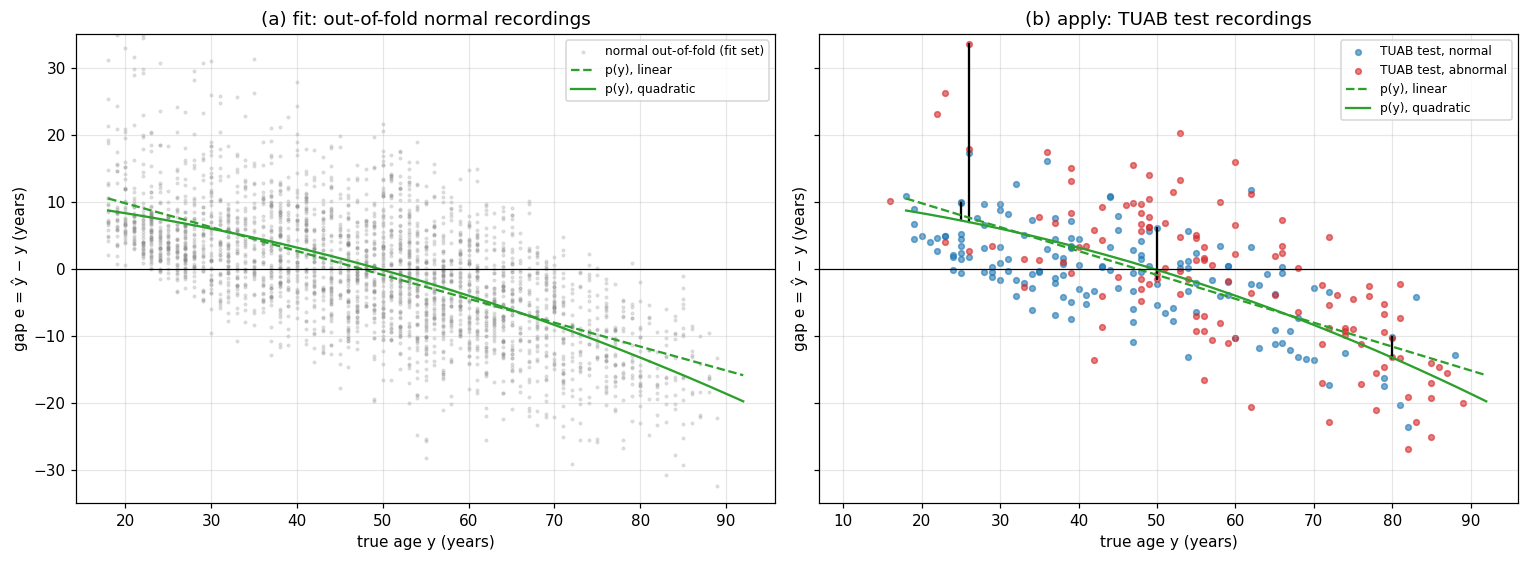

In [17]:
if psets is not None:
    grid = np.linspace(18, 92, 200)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
    ax = axes[0]
    smp = fn.sample(3000, random_state=0)
    ax.scatter(smp.true, smp.err, s=3, alpha=0.2, color="0.5", label="normal out-of-fold (fit set)")
    ax.set_title("fit: out-of-fold normal recordings")
    ax = axes[1]
    for st, col in (("normal", "tab:blue"), ("abnormal", "tab:red")):
        h = test[test.status == st]
        ax.scatter(h.true, h.err, s=14, alpha=0.6, color=col, label=f"TUAB test, {st}")
    for _, r in ex.iterrows():
        ax.plot([r.true, r.true], [r.err, np.polyval(q_quad, r.true)], color="k", lw=1.5)
    ax.set_title("apply: TUAB test recordings")
    for ax in axes:
        ax.plot(grid, np.polyval(q_lin, grid), "--", color="tab:green", label="p(y), linear")
        ax.plot(grid, np.polyval(q_quad, grid), "-", color="tab:green", label="p(y), quadratic")
        ax.axhline(0, color="k", lw=0.8)
        ax.set(xlabel="true age y (years)", ylabel="gap e = ŷ − y (years)", ylim=(-35, 35))
        ax.legend(fontsize=8)
    finish(fig, axes)

### 4.6 Step 5: score

### Table 4.8. `cvctrl` on the TUAB test set, step by step

MAE (Eq. (2.10)) in years over all 274, the 149 normal and the 125 abnormal TUAB test recordings, computed
from the corrected gaps of Eq. (4.7) for every test recording (not only the six of Table 4.7). It equals the
`cvctrl` rows of Table 5.6, which are produced by `corrected_test` (checked below the table).

In [18]:
if psets is not None:
    cols = {"raw": test.err,
            "gap lin, normal †": test.err - np.polyval(q_lin, test.true),
            "gap quad, normal †": test.err - np.polyval(q_quad, test.true),
            "recal lin, normal": apply_recal(test.pred, rc) - test.true}
    t48 = pd.DataFrame({m: {st: float(np.mean(np.abs(e if st == "all" else e[test.status == st])))
                            for st in ("all", "normal", "abnormal")} for m, e in cols.items()})
    t48.index.name = "TUAB test"
    display(numbered_table(t48, "4.8", "cvctrl step by step"))
    for m in cols:
        d = METHODS[m](psets)
        d = d[d.exp == "cvctrl"]
        assert abs(t48.loc["all", m] - d.err.abs().mean()) < 1e-9
    print("identical to corrected_test (Table 5.6) for every column")

,raw,"gap lin, normal †","gap quad, normal †","recal lin, normal"
TUAB test,,,,
all,7.10,5.70,5.59,6.98
normal,5.31,4.73,4.62,5.19
abnormal,9.23,6.87,6.74,9.11


identical to corrected_test (Table 5.6) for every column


### 4.7 The single-split runs: a linear recalibration fitted on the validation split

The phase-2 runs of the research summary (its Table 2.5) are trained once, on one train/val/test split, so they
have no out-of-fold predictions. Their `cal.` columns use the **validation split** instead
(`rs.split_run_calibration`, stored in `docs/data/phase2_calibration.csv`):
1. **Fit set:** the run's own **normal validation** recordings (291–1,388 depending on the cohort). The same
   split chose the run's best epoch, so it was used once for model selection, but it holds no test recording
   or test patient.
2. **Fit:** the linear recalibration of Eq. (2.7), $d = 1$: $y \approx a\,\hat y + b$ (here $a$, $b$ are
   the $a'$, $b'$ of Eq. (2.7)).
3. **Apply** to the run's TUAB test predictions alone, $\hat y'' = a\,\hat y + b$: no test age is read.

No quadratic and no gap correction is used for these runs.

### Table 4.9. Single-split runs: recalibration fitted on validation, applied to test

From `docs/data/phase2_calibration.csv`. `fit recordings`: normal val recordings of the run; `a`, `b`: the fitted
line; `fit ∩ test recordings / patients`: overlap with TUAB test (must be 0); `test` / `cal.`: TUAB test MAE
(years) before / after the recalibration, all / normal / abnormal recordings; `val`: the raw val MAE (never
corrected).

In [19]:
REPO = next(p for p in sys.path if os.path.isdir(os.path.join(p, "labram")))
t49 = pd.read_csv(os.path.join(REPO, "docs/data/phase2_calibration.csv")).set_index("run")
assert (t49[["fit ∩ test recordings", "fit ∩ test patients"]] == 0).all().all()
display(numbered_table(t49.style.format(precision=2).format(precision=3, subset=["a", "b"])
                       .format("{:,}", subset=["fit recordings"]), "4.9", "Single-split runs: val-fitted recalibration"))

,fit recordings,a,b,fit ∩ test recordings,fit ∩ test patients,test all,cal. all,test normal,cal. normal,test abnormal,cal. abnormal,val
run,,,,,,,,,,,,
Control,291,1.093,-3.756,0,0,8.23,8.12,6.42,6.30,10.39,10.29,7.48
Exp1,843,1.006,0.359,0,0,8.03,7.96,5.99,5.95,10.47,10.36,7.51
Exp2,395,1.104,-1.983,0,0,8.00,7.91,6.06,5.95,10.31,10.25,8.44
Exp1b,843,0.961,1.963,0,0,8.11,8.15,6.09,6.13,10.52,10.54,7.52
Exp1t,843,0.926,2.890,0,0,8.80,9.00,7.17,7.35,10.73,10.97,8.49
Exp1f,843,0.928,2.859,0,0,8.13,8.21,6.21,6.28,10.41,10.51,7.30
Exp3,"1,254",1.030,-1.649,0,0,7.26,7.23,5.57,5.53,9.28,9.26,7.58
Exp3b,"1,254",1.063,-2.295,0,0,7.70,7.48,6.17,5.96,9.51,9.29,7.81
Exp3q,"1,226",1.032,-1.432,0,0,7.37,7.29,5.74,5.67,9.30,9.22,7.61


### Table 4.10. Where each correction of the research summary was fitted and applied

| where in `brain_age_research_summary.ipynb` | runs | correction | fitted on | applied to | reads the test true age |
|---|---|---|---|---|---|
| Table 3.5 `recal, normal`; `cal.` columns of Tables 2.5–2.7 (CV rows) | 4 CV experiments | linear recalibration, Eq. (2.7) | out-of-fold **normal** recordings: in-pool test folds (`cvaugval`: val folds), 11,455 | TUAB test, median of 5 fold models | no |
| Table 3.5 `cole, normal` | 4 CV | Cole inversion, Eq. (2.5) | same | TUAB test | no |
| Table 3.5 `gap lin, all †` | 4 CV | **linear** gap correction, Eq. (2.3), $d = 1$ | out-of-fold, **all** statuses, 29,035 | TUAB test | **yes** |
| Table 3.5 `gap quad, normal †` | 4 CV | **quadratic** gap correction, $d = 2$ (Gemein et al.) | out-of-fold **normal**, 11,455 | TUAB test | **yes** |
| `cal.` columns of Table 2.5 (single-split rows) | 20 phase-2 runs | linear recalibration | the run's own **validation** split, normal recordings | the run's TUAB test predictions | no |
| every other number (val, test, CV folds) | all | none | – | – | – |

**Why not fit on the test set?** A correction fitted on the recordings it is scored on adapts to their
errors, so its MAE is optimistic, and for the † gap correction the fitted residuals are uncorrelated with age by
construction (Section 2.1). **Why the in-pool test fold and not the val fold?** In the in-pool scheme, a pool
recording's out-of-fold prediction comes from a model that neither trained on it nor chose its epoch with it.
The same recording was the val fold of the *previous* fold model (Table 4.2), whose prediction is not used.
`cvaugval` has no in-pool test fold, so its fit set is the val folds that chose its epochs. That is slightly
optimistic, but it still contains no TUAB test recording or patient.

## 5. Results of every correction on the TUAB test set

Section 4 walked through one experiment and three corrections. This section runs every correction of
Section 2 on all four CV experiments, with the same fit sets (out-of-fold) and the same test set (TUAB test).

### Table 5.1. The prediction sets of `cvctrl`

Per prediction set and status: `n` recordings, `mean age` (years), raw `MAE` and `bias` (Eq. (1.2)), `β`
(Eq. (1.3)) and `R²` (Eq. (1.4), as $1 - \operatorname{Var}(e)/\operatorname{Var}(y)$). The other three
experiments are within a few tenths of a year of these values. The out-of-fold sets form the fit set $F$;
the TUAB test row is what Tables 5.4–4.6 correct.

In [20]:
if psets is not None:
    g = psets[psets.exp == "cvctrl"]
    rows = []
    for (s, st), h in g.groupby(["set", "status"], sort=False):
        rows.append({"set": s, "status": st, "mean age": h.true.mean(), **describe(h.pred, h.true)})
    t41 = pd.DataFrame(rows).drop(columns=["R² − 1 (1.5)"]).set_index(["set", "status"]).sort_index()
    display(numbered_table(t41, "5.1", "Prediction sets of cvctrl"))

### Table 5.2. The corrections reproduce the research summary, and only † reads the test ages

Three checks.
1. **Same code.** The functions of Section 2.6 give the same corrected TUAB test predictions as
   `research_summary.py` (`bias_corrected_test`, `cole_corrected_test`, `recalibrated_test`); the largest
   difference is printed below the table and must be 0.
2. **Eq. (2.6).** With the same fit set, the Cole error equals the linear gap-corrected error divided by $a$,
   per recording (also printed).
3. **Leakage** (`rs.correction_leak_check`). `fit ∩ test recordings` / `fit ∩ test patients`: out-of-fold
   recordings that are TUAB test recordings or share a patient with one (both must be 0). `max change
   (years)`: the TUAB test true ages are permuted within each experiment and each correction is run again;
   a method that never reads the test ages returns identical predictions (max change 0).

In [21]:
if psets is not None:
    pairs = {   # this notebook's method -> the research summary's function, same fit set
        "gap lin, all †": rs.bias_corrected_test(psets, 1),
        "gap quad, normal †": rs.bias_corrected_test(psets, 2, fit_status=NORMAL),
        "cole, normal": rs.cole_corrected_test(psets, fit_status=NORMAL),
        "recal lin, normal": rs.recalibrated_test(psets, fit_status=NORMAL),
    }
    key = ["exp", "stem"]
    diff = max(float(np.max(np.abs(METHODS[m](psets).sort_values(key).pred.to_numpy()
                                   - ref.sort_values(key).pred.to_numpy()))) for m, ref in pairs.items())
    print(f"1. largest difference to research_summary.py: {diff:.2e} years")
    assert diff < 1e-9
    worst = 0.0
    for exp, g in psets.groupby("exp"):
        f = fit_set(g, NORMAL)
        t = g[g.set == TEST_SET]
        a, c = fit_cole(f.true, f.pred)
        cole_err = apply_cole(t.pred, a, c) - t.true
        gap_err = apply_gap(t.pred, t.true, fit_gap(f.true, f.err, 1)) - t.true
        worst = max(worst, float(np.max(np.abs(cole_err - gap_err / a))))         # Eq. (2.6)
    print(f"2. Eq. (2.6), max |(ŷ' − y) − e^c / a| over all test recordings: {worst:.2e} years")
    assert worst < 1e-9
    t42 = rs.correction_leak_check(psets, METHODS).set_index("method")
    assert (t42[["fit ∩ test recordings", "fit ∩ test patients"]] == 0).all().all()
    assert (t42.loc[DEPLOYABLE, "uses TUAB test true age"] == "no").all()
    display(numbered_table(t42, "5.2", "Leakage check of the corrections"))

1. largest difference to research_summary.py: 0.00e+00 years
2. Eq. (2.6), max |(ŷ' − y) − e^c / a| over all test recordings: 5.68e-14 years


,fit ∩ test recordings,fit ∩ test patients,max change (years),uses TUAB test true age
method,,,,
raw,0,0,0.00,no
"recal lin, normal",0,0,0.00,no
"recal quad, normal",0,0,0.00,no
"cole, normal",0,0,0.00,no
"cole, all",0,0,0.00,no
"gap lin, all †",0,0,26.52,yes
"gap lin, normal †",0,0,24.22,yes
"gap quad, all †",0,0,28.57,yes
"gap quad, normal †",0,0,26.34,yes


### Table 5.3. Fitted coefficients per experiment

All fitted on the experiment's out-of-fold recordings $F$ (Eq. (2.1)), years. `gap lin, all`: $q_1, q_0$ of
Eq. (2.2), $d=1$, all statuses. `gap quad, normal`: $q_2, q_1, q_0$, $d=2$, normal only. `cole, normal`:
$a, c$ of Eq. (2.5). `recal lin, normal`: $a', b'$ of Eq. (2.7), $d = 1$. `r²` is the squared correlation of
$\hat y$ and $y$ on the normal fit set and `a·a'` the product of Eq. (2.8), which must equal it.
`n normal` / `n all`: size of $F$.

In [22]:
if psets is not None:
    rows = []
    for exp in EXPS:
        g = psets[psets.exp == exp]
        fa, fn = fit_set(g), fit_set(g, NORMAL)
        q1l, q0l = fit_gap(fa.true, fa.err, 1)
        q2, q1, q0 = fit_gap(fn.true, fn.err, 2)
        a, c = fit_cole(fn.true, fn.pred)
        a2, b2 = fit_recal(fn.pred, fn.true, 1)
        rows.append({"exp": exp, "n all": len(fa), "n normal": len(fn),
                     ("gap lin, all", "q1"): q1l, ("gap lin, all", "q0"): q0l,
                     ("gap quad, normal", "q2"): q2, ("gap quad, normal", "q1"): q1, ("gap quad, normal", "q0"): q0,
                     ("cole, normal", "a"): a, ("cole, normal", "c"): c,
                     ("recal lin, normal", "a'"): a2, ("recal lin, normal", "b'"): b2,
                     "r²": np.corrcoef(fn.pred, fn.true)[0, 1] ** 2, "a·a'": a * a2})
    t43 = pd.DataFrame(rows).set_index("exp")
    t43.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in t43.columns])
    assert np.allclose(t43["r²"], t43["a·a'"])                                     # Eq. (2.8)
    display(numbered_table(t43.style.format(precision=4, na_rep="–").format(
        "{:,.0f}", subset=[("n all", ""), ("n normal", "")]), "5.3", "Fitted coefficients"))

### Table 5.4. The fitted age trend $p(y)$ of `cvctrl`, linear against quadratic

The trend Eq. (2.3) subtracts, evaluated at selected true ages $y$ (years): $p_1$ and $p_2$ of Eq. (2.2)
fitted on all or on the normal out-of-fold recordings of `cvctrl`. A positive value means the model
predicts recordings of that age too old on average. `quad − lin, normal` is where the two normal-fit
corrections differ.

In [23]:
if psets is not None:
    g = psets[psets.exp == "cvctrl"]
    ages = np.array([20, 30, 40, 50, 60, 70, 75, 80, 85])
    fits = {f"{deg} {st}": fit_gap(fit_set(g, s).true, fit_set(g, s).err, d)
            for deg, d in (("lin", 1), ("quad", 2)) for st, s in (("all", None), ("normal", NORMAL))}
    t44 = pd.DataFrame({k: np.polyval(c, ages) for k, c in fits.items()}, index=pd.Index(ages, name="true age y"))
    t44.columns = [f"p, {k}" for k in t44.columns]
    t44["quad − lin, normal"] = t44["p, quad normal"] - t44["p, lin normal"]
    display(numbered_table(t44.T, "5.4", "Fitted age trend of the gap, cvctrl"))

true age y,20,30,40,50,60,70,75,80,85
"p, lin all",12.57,8.68,4.79,0.90,-2.99,-6.87,-8.82,-10.76,-12.71
"p, lin normal",9.76,6.20,2.63,-0.93,-4.50,-8.06,-9.84,-11.63,-13.41
"p, quad all",10.17,8.12,5.38,1.95,-2.18,-6.99,-9.65,-12.49,-15.50
"p, quad normal",8.28,5.98,3.15,-0.18,-4.03,-8.39,-10.77,-13.27,-15.90
"quad − lin, normal",-1.48,-0.22,0.52,0.75,0.47,-0.33,-0.92,-1.64,-2.49


### Figure 5.1. The age trend on the out-of-fold recordings of `cvctrl`

`cvctrl`'s out-of-fold recordings, years. (a) The gap $e$ against the true age: mean gap per 5-year bin
for normal (blue) and abnormal (red) recordings, a thinned scatter of 3,000 normal recordings in grey, and
the four fitted trends $p_d$ of Eq. (2.2): linear and quadratic, fitted on all or on normal recordings.
(b) The deployable view: mean true age per 5-year bin of the **predicted** age, normal recordings, with the
linear and quadratic recalibration curves of Eq. (2.7) and the identity (dashed).

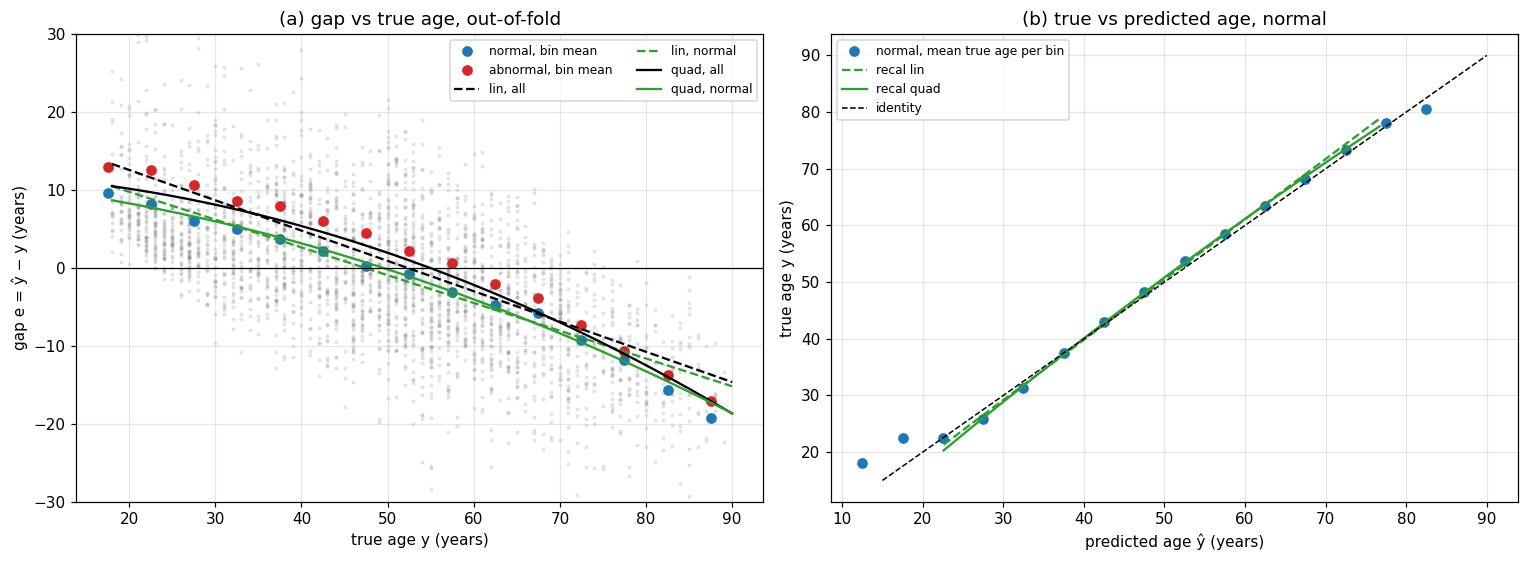

In [24]:
if psets is not None:
    g = psets[psets.exp == "cvctrl"]
    fa, fn = fit_set(g), fit_set(g, NORMAL)
    fab = fa[fa.status == "abnormal"]
    bins = np.arange(15, 95, 5)
    mid = (bins[:-1] + bins[1:]) / 2
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    ax = axes[0]
    smp = fn.sample(3000, random_state=0)
    ax.scatter(smp.true, smp.err, s=3, alpha=0.15, color="0.5")
    for d, col, lab in ((fn, "tab:blue", "normal, bin mean"), (fab, "tab:red", "abnormal, bin mean")):
        m = d.groupby(pd.cut(d.true, bins), observed=False).err.mean()
        ax.plot(mid, m, "o", color=col, label=lab)
    grid = np.linspace(18, 90, 200)
    for (deg, s, ls, col) in ((1, None, "--", "k"), (1, NORMAL, "--", "tab:green"),
                              (2, None, "-", "k"), (2, NORMAL, "-", "tab:green")):
        f = fit_set(g, s)
        ax.plot(grid, np.polyval(fit_gap(f.true, f.err, deg), grid), ls=ls, color=col,
                label=f"{'lin' if deg == 1 else 'quad'}, {'normal' if s else 'all'}")
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel="true age y (years)", ylabel="gap e = ŷ − y (years)", ylim=(-30, 30),
           title="gap vs true age, out-of-fold")
    ax.legend(fontsize=8, ncol=2)
    ax = axes[1]
    pb = np.arange(10, 100, 5)
    m = fn.groupby(pd.cut(fn.pred, pb), observed=False).true.mean()
    ax.plot((pb[:-1] + pb[1:]) / 2, m, "o", color="tab:blue", label="normal, mean true age per bin")
    pg = np.linspace(fn.pred.quantile(0.005), fn.pred.quantile(0.995), 200)
    ax.plot(pg, apply_recal(pg, fit_recal(fn.pred, fn.true, 1)), color="tab:green", ls="--", label="recal lin")
    ax.plot(pg, apply_recal(pg, fit_recal(fn.pred, fn.true, 2)), color="tab:green", label="recal quad")
    ax.plot([15, 90], [15, 90], "k--", lw=1, label="identity")
    ax.set(xlabel="predicted age ŷ (years)", ylabel="true age y (years)", title="true vs predicted age, normal")
    ax.legend(fontsize=8)
    finish(fig, axes)

### Table 5.5. Worked example: `gap quad, normal †` for one abnormal TUAB test recording of `cvctrl`

The steps of Eqs. (2.1)–(2.3) for the abnormal TUAB test recording whose true age is closest to 75 years.
`p(y)` is the quadratic trend fitted on the normal out-of-fold recordings (Table 5.3), evaluated at the
recording's true age; the corrected gap is $e^c = e - p(y)$.

In [25]:
if psets is not None:
    g = psets[psets.exp == "cvctrl"]
    fn = fit_set(g, NORMAL)
    q = fit_gap(fn.true, fn.err, 2)
    t = g[(g.set == TEST_SET) & (g.status == "abnormal")]
    r = t.iloc[(t.true - 75).abs().argmin()]
    py = float(np.polyval(q, r.true))
    t45 = pd.DataFrame([
        ("1. fit set F (Eq. (2.1))", f"{len(fn):,} normal out-of-fold recordings"),
        ("2. fitted trend (Eq. (2.2))", f"p(y) = {q[0]:.5f}·y² {q[1]:+.4f}·y {q[2]:+.2f}"),
        ("3. test recording", f"{r.stem}, abnormal, true age y = {r.true:.0f}"),
        ("   raw prediction ŷ and gap e (Eq. (1.1))", f"ŷ = {r.pred:.1f}, e = {r.err:+.1f}"),
        ("   trend at the true age p(y)", f"{py:+.1f}"),
        ("4. corrected ŷᶜ = ŷ − p(y) (Eq. (2.3))", f"{r.pred - py:.1f}"),
        ("   corrected gap eᶜ = e − p(y)", f"{r.err - py:+.1f}"),
    ], columns=["step", "value"]).set_index("step")
    display(numbered_table(t45, "5.5", "Worked example of gap quad, normal"))

,value
step,
1. fit set F (Eq. (2.1)),"11,455 normal out-of-fold recordings"
2. fitted trend (Eq. (2.2)),p(y) = -0.00257·y² -0.1023·y +11.36
3. test recording,"aaaaabdo_s003_t000, abnormal, true age y = 75"
raw prediction ŷ and gap e (Eq. (1.1)),"ŷ = 70.4, e = -4.6"
trend at the true age p(y),-10.8
4. corrected ŷᶜ = ŷ − p(y) (Eq. (2.3)),81.2
corrected gap eᶜ = e − p(y),+6.2


### Table 5.6. TUAB test MAE after each correction

MAE (Eq. (2.10)) in years on the TUAB test set (274 recordings: 149 normal, 125 abnormal), per experiment
and status, each correction fitted on the experiment's out-of-fold recordings. Deployable columns (no
†, a valid test error): `raw` (Eq. (1.2)), `recal lin / quad, normal` (Eq. (2.7)), `cole, normal / all`
(Eq. (2.5)). Gap-corrected columns (†, reads the test ages, Section 3): `gap lin / quad, all / normal`
(Eqs. (2.2)–(2.3)). The last rows are published TUAB numbers: Gemein et al. (2024) report 6.48 raw and 6.60
after their quadratic normal-fit correction on normal recordings, 12.85 on pathological ones; Engemann et
al. (2022) 7.75 on TUAB normal recordings (10-fold CV, raw). Gemein's model is trained on TUAB normal
recordings only.

In [26]:
if psets is not None:
    corrected = {m: fn(psets) for m, fn in METHODS.items()}
    rows = []
    for exp in EXPS:
        for st in ("all", "normal", "abnormal"):
            r = {"model": exp, "status": st}
            for m, d in corrected.items():
                h = d[d.exp == exp]
                h = h if st == "all" else h[h.status == st]
                r[m] = float(np.mean(np.abs(h.err)))
            rows.append(r)
    rows += [{"model": "Gemein et al. 2024 (TCN, TUAB normal)", "status": "normal", "raw": 6.48, "gap quad, normal †": 6.60},
             {"model": "Gemein et al. 2024 (TCN, TUAB normal)", "status": "abnormal", "gap quad, normal †": 12.85},
             {"model": "Engemann et al. 2022 (TUAB normal, CV)", "status": "normal", "raw": 7.75}]
    t46 = pd.DataFrame(rows).set_index(["model", "status"])[list(METHODS)]
    display(numbered_table(t46, "5.6", "TUAB test MAE after each correction"))

### Table 5.7. Mean gap by status: do abnormal recordings look older?

Mean gap (bias, Eq. (1.2)) in years on the TUAB test set after each correction. `normal` / `abnormal`:
`cvctrl`'s mean gap per status. `ab − norm, <exp>`: the abnormal minus the normal mean gap for each
experiment. The last row, `age covariate`, is $\delta$ of Eq. (2.9): the raw gap regressed on
$1, y, y^2$ and the abnormal indicator over the 274 test recordings (an inference model on the test
recordings themselves, not a correction). Mean true age of the test set: 44.6 years normal, 57.2
abnormal.

In [27]:
if psets is not None:
    order = ["raw", "recal lin, normal", "cole, normal", "gap lin, all †", "gap lin, normal †",
             "gap quad, all †", "gap quad, normal †"]
    rows = []
    for m in order:
        d = corrected[m]
        r = {"method": m}
        for exp in EXPS:
            h = d[d.exp == exp]
            mn, ma = h.err[h.status == "normal"].mean(), h.err[h.status == "abnormal"].mean()
            if exp == "cvctrl":
                r["normal, cvctrl"], r["abnormal, cvctrl"] = mn, ma
            r[f"ab − norm, {exp}"] = ma - mn
        rows.append(r)
    r = {"method": "age covariate, Eq. (2.9)"}
    for exp in EXPS:
        h = corrected["raw"][corrected["raw"].exp == exp]
        X = np.column_stack([np.ones(len(h)), h.true, h.true ** 2, (h.status == "abnormal").astype(float)])
        r[f"ab − norm, {exp}"] = float(np.linalg.lstsq(X, h.err.to_numpy(), rcond=None)[0][3])   # delta
    rows.append(r)
    t47 = pd.DataFrame(rows).set_index("method")
    t47 = t47[["normal, cvctrl", "abnormal, cvctrl"] + [f"ab − norm, {e}" for e in EXPS]]
    display(numbered_table(t47, "5.7", "Mean gap by status after each correction"))

,"normal, cvctrl","abnormal, cvctrl","ab − norm, cvaug","ab − norm, cvaugval","ab − norm, cvbase","ab − norm, cvctrl"
method,,,,,,
raw,-0.58,-1.00,-0.21,-0.26,-1.42,-0.42
"recal lin, normal",-0.50,-0.15,0.52,0.55,-0.43,0.35
"cole, normal",-2.42,3.91,6.49,6.26,5.27,6.33
"gap lin, all †",-3.56,0.91,4.63,4.47,3.73,4.48
"gap lin, normal †",-1.56,2.51,4.21,4.10,3.29,4.07
"gap quad, all †",-3.51,1.02,4.69,4.53,3.78,4.53
"gap quad, normal †",-1.55,2.70,4.38,4.27,3.47,4.25
"age covariate, Eq. (2.9)",–,–,4.68,4.59,3.64,4.50


### Figure 5.2. TUAB test gaps of `cvctrl` before and after `gap quad, normal †`

`cvctrl`'s TUAB test ensemble, 149 normal (blue) and 125 abnormal (red) recordings, years, each with its
least-squares line. (a) The raw gap $e$ (Eq. (1.1)) against the true age. (b) The gap after `gap quad,
normal †`, $e^c$ of Eq. (2.3).

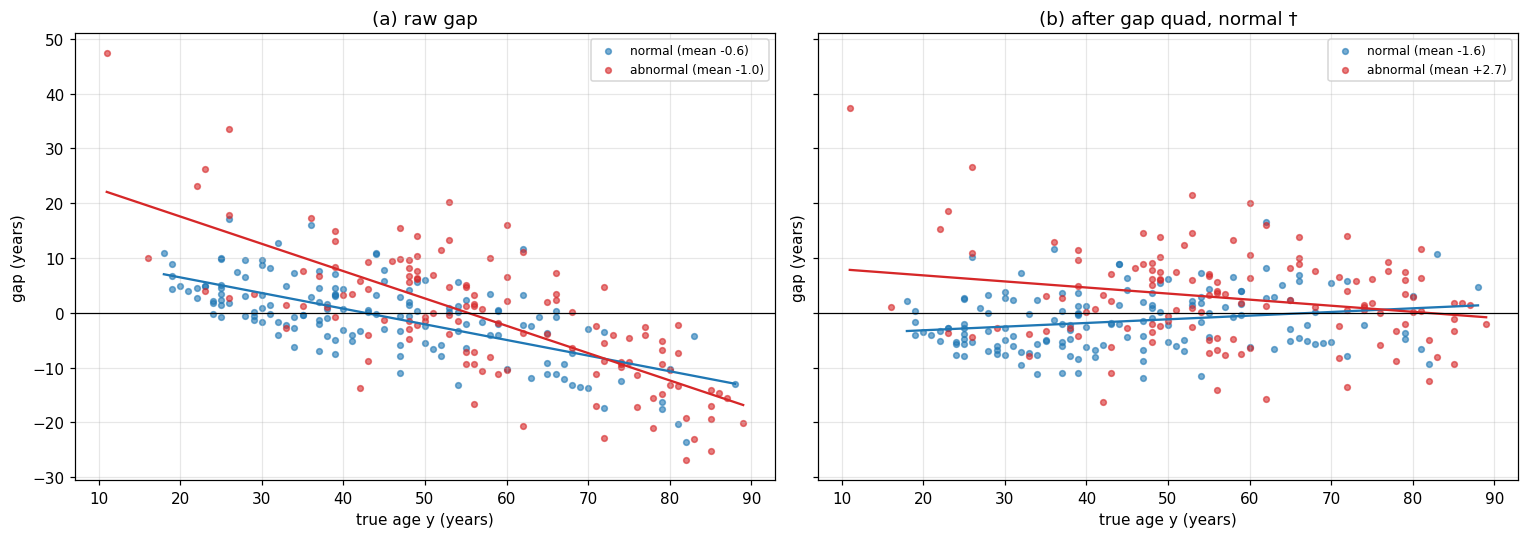

In [28]:
if psets is not None:
    raw = corrected["raw"][corrected["raw"].exp == "cvctrl"]
    cor = corrected["gap quad, normal †"][corrected["gap quad, normal †"].exp == "cvctrl"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, d, title in ((axes[0], raw, "raw gap"), (axes[1], cor, "after gap quad, normal †")):
        for st, col in (("normal", "tab:blue"), ("abnormal", "tab:red")):
            h = d[d.status == st]
            ax.scatter(h.true, h.err, s=14, alpha=0.6, color=col, label=f"{st} (mean {h.err.mean():+.1f})")
            grid = np.linspace(h.true.min(), h.true.max(), 50)
            ax.plot(grid, np.polyval(np.polyfit(h.true, h.err, 1), grid), color=col)
        ax.axhline(0, color="k", lw=0.8)
        ax.set(xlabel="true age y (years)", ylabel="gap (years)", title=title)
        ax.legend(fontsize=8)
    finish(fig, axes)

**Reading Tables 5.1–4.7 and Figures 5.1–4.2.**
* **The models regress to the mean, as Eq. (1.5) predicts.** On the normal TUEG out-of-fold recordings `cvctrl`
  has $\beta = -0.36$ and $R^2 = 0.68$ (Table 5.1), so $\beta$ is within 0.04 of $R^2 - 1$; the slope is
  steeper still on abnormal recordings ($\beta \approx -0.4$ to $-0.5$). The trend is not linear: on normal recordings the quadratic fit bends down at old age
  (Table 5.4, Figure 5.1(a)), so the linear and quadratic corrections differ by up to a few years at the
  ends of the age range and agree in the middle.
* **The corrections are leak-free in what they fit** (Table 5.2: 0 shared recordings and patients), and the
  code here is the code of the research summary (difference 0). The deployable ones (`recal`, `cole`) never
  read a test age (max change 0); every † method does (permuting the test ages moves its output by
  24–29 years).
* **Deployable corrections barely help.** `recal lin, normal` lowers the TUAB test MAE by about 0.1–0.2
  years in every experiment and status (Table 5.6); `recal quad` is about the same. The models are close
  to least-squares calibrated already: $a' \approx 1.06$ (Table 5.3), as Eq. (2.8) predicts when $a$ is
  close to $r^2$. **Cole makes every error worse** (by 1.5–1.8 years overall, more when fitted on all
  recordings) because it divides the detrended error by $a \approx 0.63$–$0.65$ (Eq. (2.6), checked to
  machine precision).
* **The † corrections shrink the numbers a lot, for the reason of Section 3.** `gap quad, normal †` brings
  `cvctrl` from 5.31 / 9.23 to 4.62 / 6.74 on normal / abnormal recordings (Table 5.6). These numbers compare only
  with other †-numbers, e.g. Gemein et al.'s 6.60 / 12.85, never with a raw or recalibrated MAE.
* **Linear or quadratic.** The quadratic gives a lower † number than the linear fit in every experiment
  (normal: 4.48–4.77 against 4.58–4.86 with the normal fit). The two trends differ by up to 2.5 years at the
  ends of the age range and by under 1 year between 30 and 70 (Table 5.4).
* **All or normal.** The fit set fixes the **zero** of the corrected gap. Fitted on normal recordings, 0 means
  "as expected for a normal brain of this age": `cvctrl`'s normal test recordings sit at −1.6 and the abnormal
  ones at +2.7 years (Table 5.7). Fitted on all recordings, 0 means "as expected for an average patient of
  this age", and the curve moves up by about 2 years (Table 5.4): normal −3.6, abnormal +0.9. That level shift
  is why the all-fit gives the lower abnormal and the higher normal number in Table 5.6. The **difference**
  between the groups barely depends on the fit set (3.7–4.7 years with either). For a pathology question the
  normal fit is the meaningful reference, which is Gemein et al.'s choice.
* **Abnormal recordings look older, once age is accounted for.** Raw, the abnormal mean gap is 0.2–1.4 years
  *below* the normal one (Table 5.7), because abnormal patients are 12.6 years older on average and old people
  are predicted too young (Figure 5.2(a)). Remove the age trend and the abnormal recordings sit 3.3–4.4 years
  *above* the normal ones (normal fit; Figure 5.2(b)). The age-covariate model of Eq. (2.9) gives the same
  answer, 3.6–4.7 years, without any correction (last row of Table 5.7), which is why Le et al. (2018) and
  Butler et al. (2021) recommend it.
* **This is the opposite sign of Gemein et al.** They find that pathological TUAB subjects have a mean gap of
  about −5 years against −1 for non-pathological ones (difference −4.01): pathological brains look
  **younger**. They also note that age bias remained after their correction. A plausible reason for the
  opposite sign: pathological subjects are older, so any regression to the mean left on their evaluation set
  pulls the pathological gap down, as it does for our raw gaps. Our age-adjusted comparisons (normal-fit
  correction and Eq. (2.9)) remove it. Their model is also trained on normal recordings only, so abnormal
  EEG is out of its training distribution, while the LaBraM CV models train on both. (The research
  summary's Table 3.5 reading says the two results agree; the sign says they do not.)

## 6. The literature

### Table 6.1. Age-bias correction in the brain-age literature

| paper | correction | fitted on | uses the true age when applied | what it says about reporting | here |
|---|---|---|---|---|---|
| Cole et al. 2018, *Mol. Psychiatry* | $\hat y' = (\hat y - c)/a$ from $\hat y \approx a y + c$ | training set | no | corrected age estimate | `cole`, Eq. (2.5) |
| Le et al. 2018, *Front. Aging Neurosci.* | none; age (and age²) as covariate in the downstream model | – | – | correcting the gap and not adjusting for age can give spurious effects | Eq. (2.9) |
| Liang et al. 2019, *Hum. Brain Mapp.* | regress the gap on age (general linear model), subtract | training data | yes | bias is a statistical artefact of regression (regression dilution) | `gap lin` |
| Smith et al. 2019, *NeuroImage* | $\delta_2$: gap orthogonalised to $y$; $\delta_{2q}$: to $y$ and $y^2$ (quadratic) | the analysed population | yes | recommends the quadratic (and further) terms to catch non-linear ageing | `gap lin` / `gap quad` |
| Beheshti et al. 2019, *NeuroImage: Clin.* | offset $= \alpha\,y + \beta$ from the gap of the training set; $\hat y - \text{offset}$ | training set (CV) | yes | robust correction for small samples | `gap lin`, Eq. (2.4) |
| de Lange & Cole 2020, *NeuroImage: Clin.* | $\hat y + [\,y - (\alpha y + \beta)\,]$ | training set | yes | Beheshti and de Lange are the same; correction lowers MAE because it uses age; same result as age covariate | `gap lin`, Eq. (2.4) |
| Butler et al. 2021, *Hum. Brain Mapp.* | analyses the "modified gap" (age regressed out) | – | yes | corrected $R^2$/MAE are inflated, $R^2 > 0.85$ almost regardless of model; use age as covariate | Section 3, Eq. (2.9) |
| de Lange et al. 2022, *Hum. Brain Mapp.* | evaluates metrics with/without correction | – | – | metrics depend on age range and correction; report uncorrected metrics | Table 5.6 |
| Zhang et al. 2023, *NeuroImage: Clin.* | age-level correction | training set | yes | bias remains at a fixed age level after the usual corrections | not used |
| Gemein et al. 2024, *Imaging Neurosci.* (TUAB EEG, TCN) | quadratic regression of the gap on age, fitted during CV on the non-pathological training data, applied directly after prediction | normal training recordings | yes | 6.48 → 6.60 years MAE on normal TUAB eval, 12.85 on pathological; pathological gap −5 vs −1 years | `gap quad, normal` |
| Engemann et al. 2022, *NeuroImage* (M/EEG benchmark, incl. TUAB) | none | – | – | raw MAE, 7.75 years on TUAB normal (CV) | `raw` |

**What Gemein et al. did, in this notebook's terms.** They train a temporal convolutional network on the
non-pathological TUAB recordings only, and fit a quadratic $p_2$ (Eq. (2.2), $d = 2$) to the (age, gap) pairs
of its cross-validation predictions, which are therefore non-pathological too. They apply it "directly after prediction and prior to computing any scores", with each
recording's chronological age (Eq. (2.3)), and cite Smith et al. (2019) for the reason. All their reported
MAEs (6.60 normal, 12.85 pathological) and brain-age gaps are therefore † numbers, comparable with
`gap quad, normal †` here and not with a raw MAE. Two differences remain: they train on normal
recordings only, so their abnormal recordings are out of distribution (hence 12.85), while the LaBraM CV
models train on both; and their correction **raised** their normal MAE slightly (6.48 → 6.60) whereas
here it lowers it by 0.7–1.0 years (Table 5.6). A model trained on normal recordings only with a small age trend
has little to remove, and transfer of the CV-fitted polynomial to the evaluation set adds noise. The
LaBraM models, trained on a pool where half the recordings are abnormal, have a steeper trend on normal
recordings (Table 5.3), which the correction removes using the true age.

**References** (DOI links):
* Beheshti, I., Nugent, S., Potvin, O., Duchesne, S. (2019). Bias-adjustment in neuroimaging-based brain age frameworks: a robust scheme. *NeuroImage: Clinical* 24, 102063. [doi:10.1016/j.nicl.2019.102063](https://doi.org/10.1016/j.nicl.2019.102063)
* Butler, E. R., et al. (2021). Pitfalls in brain age analyses. *Human Brain Mapping* 42(13), 4092–4101. [doi:10.1002/hbm.25533](https://doi.org/10.1002/hbm.25533)
* Cole, J. H., et al. (2018). Brain age predicts mortality. *Molecular Psychiatry* 23, 1385–1392. [doi:10.1038/mp.2017.62](https://doi.org/10.1038/mp.2017.62)
* de Lange, A.-M. G., Cole, J. H. (2020). Commentary: Correction procedures in brain-age prediction. *NeuroImage: Clinical* 26, 102229. [doi:10.1016/j.nicl.2020.102229](https://doi.org/10.1016/j.nicl.2020.102229)
* de Lange, A.-M. G., et al. (2022). Mind the gap: performance metric evaluation in brain-age prediction. *Human Brain Mapping* 43(10), 3113–3129. [doi:10.1002/hbm.25837](https://doi.org/10.1002/hbm.25837)
* Engemann, D. A., et al. (2022). A reusable benchmark of brain-age prediction from M/EEG resting-state signals. *NeuroImage* 262, 119521. [doi:10.1016/j.neuroimage.2022.119521](https://doi.org/10.1016/j.neuroimage.2022.119521)
* Gemein, L. A. W., Schirrmeister, R. T., Boedecker, J., Ball, T. (2024). Brain age revisited: investigating the state vs. trait hypotheses of EEG-derived brain-age dynamics with deep learning. *Imaging Neuroscience* 2, 1–22. [doi:10.1162/imag_a_00210](https://doi.org/10.1162/imag_a_00210)
* Le, T. T., et al. (2018). A nonlinear simulation framework supports adjusting for age when analyzing BrainAGE. *Frontiers in Aging Neuroscience* 10, 317. [doi:10.3389/fnagi.2018.00317](https://doi.org/10.3389/fnagi.2018.00317)
* Liang, H., Zhang, F., Niu, X. (2019). Investigating systematic bias in brain age estimation with application to post-traumatic stress disorders. *Human Brain Mapping* 40(11), 3143–3152. [doi:10.1002/hbm.24588](https://doi.org/10.1002/hbm.24588)
* Smith, S. M., Vidaurre, D., Alfaro-Almagro, F., Nichols, T. E., Miller, K. L. (2019). Estimation of brain age delta from brain imaging. *NeuroImage* 200, 528–539. [doi:10.1016/j.neuroimage.2019.06.017](https://doi.org/10.1016/j.neuroimage.2019.06.017)
* Zhang, B., Zhang, S., Feng, J., Zhang, S. (2023). Age-level bias correction in brain age prediction. *NeuroImage: Clinical* 37, 103319. [doi:10.1016/j.nicl.2023.103319](https://doi.org/10.1016/j.nicl.2023.103319)

## 7. Summary and recommendations

* **Where the corrections were fitted and applied (Section 4, Table 4.10).** CV experiments: fitted on the
  out-of-fold predictions of the CV pool (in-pool test folds; `cvaugval`: val folds), all 29,035 recordings
  or the 11,455 normal ones, and applied to the 274 TUAB test recordings, which are in no fold. Single-split
  runs: only a linear recalibration, fitted on the run's own normal validation recordings and applied to its
  test predictions. Nothing is fitted on the test set, and no validation MAE is corrected.
* **The bias is expected.** A least-squares age model has gap slope $\beta = R^2 - 1$ (Eq. (1.5)). The LaBraM
  CV models sit on that line ($\beta \approx -0.36$, $r^2 \approx 0.68$ on normal out-of-fold recordings).
* **Two families of correction, with different purposes.**
  * *Age estimation* (deployable, reads only $\hat y$): recalibration (Eq. (2.7)) is the least-squares
    optimum and gains 0.1–0.2 years here; Cole's inversion (Eq. (2.5)) removes the trend but inflates the
    error by $1/a$ (Eq. (2.6)) and is worse than raw. Report the raw MAE, optionally the recalibrated one.
  * *Brain-age gap* (†, reads the true age $y$): linear or quadratic gap correction (Eqs. (2.2)–(2.3)). Its
    "MAE" is not a prediction error: a constant predictor scores 0 (Eq. (3.1), Table 3.1). Use it for gap
    analyses and to compare with papers that report it (Gemein et al.), always marked.
* **Linear or quadratic?** The quadratic catches the bend of the gap at the ends of the age range (Table 5.4,
  Figure 5.1(a)); in the middle they agree. Smith et al. and Gemein et al. use the quadratic.
* **Fit on normal recordings** when the question is about pathology: the corrected gap then measures the
  deviation from a normal brain of the same age. Abnormal recordings come out 3.3–4.4 years older than
  normal ones (Table 5.7). Fitting on all recordings moves the zero to the average patient but leaves the
  group difference about the same. Gemein et al. report the opposite sign (pathological 4 years younger),
  probably because age bias was left in their comparison (Section 6).
* **Fit on held-out predictions, never on the test set.** Here: out-of-fold predictions, 0 shared recordings or
  patients with TUAB test (Table 5.2).
* **For group statistics**, adding age (and age²) as a covariate (Eq. (2.9)) gives the same group effect as the
  normal-fit gap correction without any post-hoc step (Table 5.7, last row).